In [1]:
import numpy as np
from astropy.io import fits
from astropy.wcs import WCS
from astropy.coordinates import SkyCoord
import astropy.units as u
import pandas as pd
import os
import matplotlib.pyplot as plt
import matplotlib as mpl
import math as math
import numpy as np
from scipy.optimize import curve_fit
from scipy.ndimage import uniform_filter1d
from scipy.signal import find_peaks
from pyspeckit.spectrum.units import SpectroscopicAxis
import pybaselines
import itertools
from specutils.manipulation import FluxConservingResampler
from specutils import Spectrum1D
from pybaselines.polynomial import modpoly
from sqlalchemy import create_engine, inspect, MetaData, Table, text
import warnings
from astropy.utils.exceptions import AstropyWarning
from striprtf.striprtf import rtf_to_text
from pathlib import Path
from itertools import combinations
import psutil

# Extracting spectra

In [2]:
def extract(cube_file, output_dir, higal_df, lon_min, lon_max):

    lat_min = -1
    lat_max = 1

    with fits.open(cube_file, ignore_missing_simple=True) as hdul:
        cube_data = hdul[0].data
        header = hdul[0].header
        wcs = WCS(header)

    CRVAL3 = header['CRVAL3']
    CRPIX3 = header['CRPIX3']
    CDELT3 = header['CDELT3']
    NAXIS3 = header['NAXIS3']

    v_min = CRVAL3 + (1 - CRPIX3) * CDELT3
    v_max = CRVAL3 + (NAXIS3 - CRPIX3) * CDELT3

    # Select Hi-GAL clumps within the cube's longitude range
    df = higal_df[
        (higal_df["GLON"] >= lon_min) &
        (higal_df["GLON"] < lon_max)
    ]

    df = df[
        (df["GLAT"] >= lat_min) &
        (df["GLAT"] < lat_max)
    ]

    df = df[
        (df["VLSR"] >= v_min) &
        (df["VLSR"] < v_max)
    ]

    for index, row in df.iterrows():

        sky_coord = SkyCoord(
            l=row["GLON"] * u.deg,
            b=row["GLAT"] * u.deg,
            frame="galactic"
        )

        # Use celestial WCS for a spectral cube
        x, y = sky_coord.to_pixel(wcs.celestial, origin=0)

        x, y = int(np.round(x).item()), int(np.round(y).item())

        # Skip clumps outside the image
        if not (0 <= x < cube_data.shape[2] and
                0 <= y < cube_data.shape[1]):
            continue

        x_min = max(x - 1, 0)
        x_max = min(x + 2, cube_data.shape[2])

        y_min = max(y - 1, 0)
        y_max = min(y + 2, cube_data.shape[1])

        subcube = cube_data[:, y_min:y_max, x_min:x_max]

        spectra = np.nanmean(subcube, axis=(1, 2))

        # Extract the spectral axis from the original cube WCS
        spectral_wcs = wcs.sub(["spectral"])

        # Create a FITS header containing the spectral WCS
        spectral_header = spectral_wcs.to_header()

        # Save the spectrum with its velocity/frequency information
        hdu = fits.PrimaryHDU(
            data=spectra,
            header=spectral_header
        )

        output_path = (
            f"{output_dir}/{molecule}_{row['DESIGNATION']}_spec.fits"
        )

        hdu.writeto(output_path, overwrite=True)

In [33]:
## Doing this instead of the SQL approach James had

path = "/Users/kyriakos.trakakis/Downloads/Other_stuff/"
filename = "HiGAL_360_clump_catalogue.tab"

# Read column names from the header
with open(path + filename, "r") as f:
    header = f.readline()

columns = [
    col.strip()
    for col in header.strip().strip("|").split("|")
]

# Read data using whitespace separators
higal_df = pd.read_csv(
    path + filename,
    sep=r"\s+",
    skiprows=3,
    names=columns,
    na_values=["-"],
    low_memory=False
)

# Plotting spectra

In [3]:
def gaus(x,a,mu,sigma):
	return a*np.exp(-(x-mu)**2/(2*sigma**2))

def gaus3(x,a1,mu1,sigma1,a2,mu2,sigma2,a3,mu3,sigma3):
	return a1*np.exp(-(x-mu1)**2/(2*sigma1**2)) + a2*np.exp(-(x-mu2)**2/(2*sigma2**2)) +a3*np.exp(-(x-mu3)**2/(2*sigma3**2))

def gaus2(x,a1,mu1,sigma1,a2,mu2,sigma2):
	return a1*np.exp(-(x-mu1)**2/(2*sigma1**2)) + a2*np.exp(-(x-mu2)**2/(2*sigma2**2))

def gaussian_sum(x, *params):
    """
    Sum of Gaussian components.

    params = [a1, mu1, sigma1, a2, mu2, sigma2, ...]
    """
    result = np.zeros_like(x, dtype=float)

    for i in range(0, len(params), 3):
        amplitude, mean, sigma = params[i:i+3]

        result += amplitude * np.exp(
            -0.5 * ((x - mean) / sigma)**2
        )

    return result


def plot_spectra(
    higal_df,
    spectra_dir,
    output_dir,
    output_file,
    vmin=-170,
    vmax=170,
    velocity_col="VLSR",
    max_components=3,
    noise_threshold=3.5,
    velocity_unit="km/s",
    max_sigma = 10.5
):

    os.makedirs(output_dir, exist_ok=True)


    # --------------------------------------------------
    # Prepare Hi-GAL catalogue
    # --------------------------------------------------

    higal_df = higal_df[higal_df['VLSR'] >= -170]
    higal_df = higal_df[(higal_df['GLAT'] > -1) & (higal_df['GLAT'] < 1)]
    catalogue = higal_df.copy()

    catalogue["DESIGNATION"] = (
        catalogue["DESIGNATION"].astype(str).str.strip()
    )

    # Only use the velocity column if it exists
    has_velocity = velocity_col in catalogue.columns


    # Index by designation for fast lookups
    catalogue = (
        catalogue.drop_duplicates(subset="DESIGNATION")
        .set_index("DESIGNATION")
    )

    # --------------------------------------------------
    # Find extracted spectra
    # --------------------------------------------------

    spectra_files = sorted([
        f for f in os.listdir(spectra_dir)
        if f.endswith("_spec.fits")
        #and f.startswith(("12CO_", "13CO_", "C18O_"))
        and f.startswith(molecule)

    ])

    print(f"Number of spectra found: {len(spectra_files)}")

    results = []

    ## So far so good, it reads all of them
    
    # --------------------------------------------------
    # Process each spectrum
    # --------------------------------------------------

    for number, spectra_file in enumerate(spectra_files, start=1):

        if number % 100 == 0:  ## Trial if
            ram_gb = process.memory_info().rss / 1024**3

            print(
            f"Spectrum {number}/{len(spectra_files)} "
            f"| RAM: {ram_gb:.2f} GB"
            )
    
        print(f"\nProcessing: {spectra_file}")

        file_path = os.path.join(spectra_dir, spectra_file)

        # Extract molecule and source name
        stem = spectra_file.removesuffix("_spec.fits")
        molecule_type, object_name = stem.split("_", 1)

        # ----------------------------------------------
        # Read FITS spectrum
        # ----------------------------------------------

        try:
            with fits.open(file_path) as hdul:
                Tmb = np.asarray(
                    hdul[0].data,
                    dtype=float
                ).squeeze()

                hd = hdul[0].header.copy()

            if Tmb.ndim != 1:
                print("Skipping: FITS data is not 1D.")
                continue

            # ------------------------------------------
            # Construct velocity axis
            # ------------------------------------------

            # Our earlier extraction function retained
            # the original cube header, so CRPIX3,
            # CRVAL3 and CDELT3 may still be present.
            #
            # Prefer axis 1 for a proper 1D FITS spectrum.

            # Read the spectral WCS from the extracted spectrum
            spectral_wcs = WCS(hd).spectral

            # Construct the velocity axis in km/s
            channels = np.arange(len(Tmb))

            xaxis = spectral_wcs.pixel_to_world(channels).to(u.km / u.s).value

            # ------------------------------------------
            # Restrict velocity range
            # ------------------------------------------

            valid = (
                np.isfinite(xaxis)
                & (xaxis >= vmin)
                & (xaxis <= vmax)
            )

            xaxis = xaxis[valid]
            Tmb = Tmb[valid]

            if len(Tmb) < 10:
                print("Skipping: insufficient channels.")
                continue

            # ------------------------------------------
            # Smooth spectrum
            # ------------------------------------------

            # Hanning smoothing, 5 channels
            window = np.hanning(5)
            window /= window.sum()

            # Fill missing values for smoothing
            finite = np.isfinite(Tmb)

            if finite.sum() < 10:
                print("Skipping: insufficient valid data.")
                continue

            Tmb_filled = np.interp(
                np.arange(len(Tmb)),
                np.flatnonzero(finite),
                Tmb[finite]
            )

            y = np.convolve(
                np.pad(Tmb_filled, 2, mode="reflect"),
                window,
                mode="valid"
            )

            # ------------------------------------------
            # Estimate RMS noise
            # ------------------------------------------

            # Robust estimate from negative fluctuations
            median = np.median(y)
            mad = np.median(np.abs(y - median))

            noise = 1.4826 * mad

            if not np.isfinite(noise) or noise <= 0:
                print("Skipping: invalid noise estimate.")
                continue

            # ------------------------------------------
            # Find emission peaks
            # ------------------------------------------

            peaks, properties = find_peaks(
                y,
                height=noise * noise_threshold,
                prominence=noise * noise_threshold,
                width=3
            )

            # Keep strongest peaks if too many
            if len(peaks) > max_components:
                strongest = np.argsort(
                    properties["peak_heights"]
                )[-max_components:]

                peaks = peaks[strongest]

            peaks = np.sort(peaks)

            n_components = len(peaks)

            if n_components == 0:
                print("No significant Gaussian peaks.")
                continue

            # ------------------------------------------
            # Initial guesses and parameter bounds
            # ------------------------------------------

            dv_kms = np.median(np.abs(np.diff(xaxis)))

            min_sigma = max(dv_kms / 10, 1e-4)
            max_sigma = 10.5  # km/s

            width_guess = np.clip(
                max(0.5, 2 * dv_kms),
                min_sigma + 1e-6,
                max_sigma - 1e-6
            )

            guesses = []
            lower_bounds = []
            upper_bounds = []

            for peak in peaks:

                guesses.extend([
                    y[peak],         # Amplitude
                    xaxis[peak],     # Mean velocity
                    width_guess      # Sigma
                ])

                lower_bounds.extend([
                    0.0,             # Minimum amplitude
                    xaxis.min(),     # Minimum velocity
                    min_sigma        # Minimum width
                ])

                upper_bounds.extend([
                    np.inf,          # Maximum amplitude
                    xaxis.max(),     # Maximum velocity
                    max_sigma        # Maximum width
                ])

            # Check parameter dimensions
            assert len(guesses) == len(lower_bounds) == len(upper_bounds), (
                f"Parameter mismatch: "
                f"guesses={len(guesses)}, "
                f"lower={len(lower_bounds)}, "
                f"upper={len(upper_bounds)}"
            )

            # ------------------------------------------
            # Fit Gaussian components
            # ------------------------------------------

            try:
                popt, pcov = curve_fit(
                    gaussian_sum,
                    xaxis,
                    y,
                    p0=guesses,
                    bounds=(lower_bounds, upper_bounds),
                    sigma=np.full_like(y, noise),
                    absolute_sigma=True,
                    maxfev=20000
                )

            except Exception as e:
                print(f"Gaussian fit failed: {e}")
                continue

            amplitudes = popt[0::3]
            mean_velocities = popt[1::3]
            widths = popt[2::3]

            # ------------------------------------------
            # Look up catalogue velocity
            # ------------------------------------------

            higal_v = np.nan

            if has_velocity and object_name in catalogue.index:
                higal_v = catalogue.at[
                    object_name, velocity_col
                ]

            # ------------------------------------------
            # Save fit parameters
            # ------------------------------------------

            results.append({
                "Number": number,
                "Object Name": object_name,
                "Molecule Type": molecule_type,
                "Num Components": n_components,
                "Amplitudes (K)": ", ".join(
                    f"{a:.3f}" for a in amplitudes
                ),
                "Mean Velocities (km/s)": ", ".join(
                    f"{v:.3f}" for v in mean_velocities
                ),
                "Widths (km/s)": ", ".join(
                    f"{s:.3f}" for s in widths
                ),
                "HiGAL VLSR (km/s)": higal_v
            })

            # ------------------------------------------
            # Plot spectrum and fit
            # ------------------------------------------

            fig, ax = plt.subplots(figsize=(10, 5))

            ax.step(
                xaxis,
                y,
                where="mid",
                color="tab:blue",
                label="Observed spectrum"
            )

            ax.plot(
                xaxis,
                gaussian_sum(xaxis, *popt),
                color="red",
                linewidth=2,
                label="Total Gaussian fit"
            )

            # Individual components
            for i in range(n_components):

                a, mu, sigma = popt[3*i:3*i+3]

                component = gaussian_sum(
                    xaxis, a, mu, sigma
                )

                ax.plot(
                    xaxis,
                    component,
                    linestyle="--",
                    alpha=0.7,
                    label=f"Component {i+1}"
                )

            # Catalogue velocity
            if np.isfinite(higal_v):
                ax.axvline(
                    higal_v,
                    color="magenta",
                    linestyle=":",
                    linewidth=2,
                    label=f"Hi-GAL VLSR = {higal_v:.2f}"
                )

            # Fit parameters
            param_lines = []

            for i in range(n_components):

                a, mu, sigma = popt[3*i:3*i+3]

                param_lines.append(
                    f"Component {i+1}: "
                    f"A={a:.2f} K, "
                    f"V={mu:.2f} km/s, "
                    f"σ={sigma:.2f} km/s"
                )

            param_text = "\n".join(param_lines)

            ax.text(
                0.02,
                0.97,
                f"RMS = {noise:.3f} K\n\n{param_text}",
                transform=ax.transAxes,
                va="top",
                fontsize=9,
                bbox=dict(
                    facecolor="white",
                    alpha=0.85,
                    edgecolor="gray"
                )
            )

            ax.set_xlim(vmin, vmax)
            ax.set_xlabel("Velocity (km/s)")
            ax.set_ylabel(r"$T_{\rm mb}$ (K)")
            ax.set_title(f"{molecule_type} — {object_name}")
            ax.legend(loc="upper right")
            ax.grid(alpha=0.2)

            plt.tight_layout()

            plot_path = os.path.join(
                output_dir,
                f"{stem}.png"
            )

            fig.savefig(
                plot_path,
                dpi=150,
                bbox_inches="tight"
            )

            plt.close(fig)

            print(
                f"Successfully fitted {n_components} "
                f"components."
            )

        except Exception as e:
            print(f"Failed to process {spectra_file}: {e}")

    # --------------------------------------------------
    # Save all fitted parameters
    # --------------------------------------------------

    results_df = pd.DataFrame(results)

    results_df.to_csv(
        output_file,
        sep="\t",
        index=False
    )

    print(
        f"\nFinished. {len(results_df)} spectra fitted."
    )

    return results_df

In [4]:
## Doesn't seem to be doing much different but maybe we can switch to this
## Subtracts spectra before trying fitting again

def iterative_gaussian_fit(
    x, y, noise,
    max_components=3,
    noise_threshold=3.5,
    max_sigma=10.5
):
    dv = np.median(np.abs(np.diff(x)))
    min_sigma = max(dv / 10, 1e-4)
    width_guess = np.clip(
        max(0.5, 2 * dv),
        min_sigma * 1.01,
        max_sigma * 0.9
    )

    params = []
    residual = y.copy()

    for n in range(1, max_components + 1):

        # Find significant positive peaks in residual
        peaks, properties = find_peaks(
            residual,
            height=noise_threshold * noise,
            prominence=noise_threshold * noise,
            width=3
        )

        if len(peaks) == 0:
            break

        # Strongest residual peak
        peak = peaks[np.argmax(residual[peaks])]

        # Add a new Gaussian initial guess
        params.extend([
            residual[peak],
            x[peak],
            width_guess
        ])

        lower_bounds = []
        upper_bounds = []

        for _ in range(n):
            lower_bounds.extend([
                0.0,
                x.min(),
                min_sigma
            ])

            upper_bounds.extend([
                np.inf,
                x.max(),
                max_sigma
            ])

        try:
            popt, pcov = curve_fit(
                gaussian_sum,
                x,
                y,  # Fit the ORIGINAL spectrum
                p0=params,
                bounds=(lower_bounds, upper_bounds),
                sigma=np.full_like(y, noise),
                absolute_sigma=True,
                maxfev=20000
            )

        except (RuntimeError, ValueError) as e:
            print(f"Fit with {n} components failed: {e}")
            break

        # Update parameters after simultaneous refitting
        params = popt.tolist()

        # Calculate new residual
        residual = y - gaussian_sum(x, *popt)

    if len(params) == 0:
        return None, None, residual

    # Sort components by central velocity
    components = np.array(params).reshape(-1, 3)
    components = components[np.argsort(components[:, 1])]

    popt = components.flatten()

    return popt, len(components), residual


def plot_spectra_re(
    higal_df,
    spectra_dir,
    output_dir,
    output_file,
    vmin=-170,
    vmax=170,
    velocity_col="VLSR",
    max_components=3,
    noise_threshold=3.5,
    velocity_unit="km/s",
    max_sigma = 10.5
):

    os.makedirs(output_dir, exist_ok=True)


    # --------------------------------------------------
    # Prepare Hi-GAL catalogue
    # --------------------------------------------------

    higal_df = higal_df[higal_df['VLSR'] >= -170]
    higal_df = higal_df[(higal_df['GLAT'] > -1) & (higal_df['GLAT'] < 1)]
    catalogue = higal_df.copy()

    catalogue["DESIGNATION"] = (
        catalogue["DESIGNATION"].astype(str).str.strip()
    )

    # Only use the velocity column if it exists
    has_velocity = velocity_col in catalogue.columns


    # Index by designation for fast lookups
    catalogue = (
        catalogue.drop_duplicates(subset="DESIGNATION")
        .set_index("DESIGNATION")
    )

    # --------------------------------------------------
    # Find extracted spectra
    # --------------------------------------------------

    spectra_files = sorted([
        f for f in os.listdir(spectra_dir)
        if f.endswith("_spec.fits")
        #and f.startswith(("12CO_", "13CO_", "C18O_"))
        and f.startswith(molecule)
    ])

    print(f"Number of spectra found: {len(spectra_files)}")

    results = []

    ## So far so good, it reads all of them
    
    # --------------------------------------------------
    # Process each spectrum
    # --------------------------------------------------

    for number, spectra_file in enumerate(spectra_files, start=1):

        if number % 100 == 0:  ## Trial if
            ram_gb = process.memory_info().rss / 1024**3

            print(
            f"Spectrum {number}/{len(spectra_files)} "
            f"| RAM: {ram_gb:.2f} GB"
            )
    
        print(f"\nProcessing: {spectra_file}")

        file_path = os.path.join(spectra_dir, spectra_file)

        # Extract molecule and source name
        stem = spectra_file.removesuffix("_spec.fits")
        molecule_type, object_name = stem.split("_", 1)

        # ----------------------------------------------
        # Read FITS spectrum
        # ----------------------------------------------

        try:
            with fits.open(file_path) as hdul:
                Tmb = np.asarray(
                    hdul[0].data,
                    dtype=float
                ).squeeze()

                hd = hdul[0].header.copy()

            if Tmb.ndim != 1:
                print("Skipping: FITS data is not 1D.")
                continue

            # ------------------------------------------
            # Construct velocity axis
            # ------------------------------------------

            # Our earlier extraction function retained
            # the original cube header, so CRPIX3,
            # CRVAL3 and CDELT3 may still be present.
            #
            # Prefer axis 1 for a proper 1D FITS spectrum.

            # Read the spectral WCS from the extracted spectrum
            spectral_wcs = WCS(hd).spectral

            # Construct the velocity axis in km/s
            channels = np.arange(len(Tmb))

            xaxis = spectral_wcs.pixel_to_world(channels).to(u.km / u.s).value

            # ------------------------------------------
            # Restrict velocity range
            # ------------------------------------------

            valid = (
                np.isfinite(xaxis)
                & (xaxis >= vmin)
                & (xaxis <= vmax)
            )

            xaxis = xaxis[valid]
            Tmb = Tmb[valid]

            if len(Tmb) < 10:
                print("Skipping: insufficient channels.")
                continue

            # ------------------------------------------
            # Smooth spectrum
            # ------------------------------------------

            # Hanning smoothing, 5 channels
            window = np.hanning(5)
            window /= window.sum()

            # Fill missing values for smoothing
            finite = np.isfinite(Tmb)

            if finite.sum() < 10:
                print("Skipping: insufficient valid data.")
                continue

            Tmb_filled = np.interp(
                np.arange(len(Tmb)),
                np.flatnonzero(finite),
                Tmb[finite]
            )

            y = np.convolve(
                np.pad(Tmb_filled, 2, mode="reflect"),
                window,
                mode="valid"
            )

            # ------------------------------------------
            # Estimate RMS noise
            # ------------------------------------------

            # Robust estimate from negative fluctuations
            median = np.median(y)
            mad = np.median(np.abs(y - median))

            noise = 1.4826 * mad

            if not np.isfinite(noise) or noise <= 0:
                print("Skipping: invalid noise estimate.")
                continue

            # ------------------------------------------
            # Iterative Gaussian decomposition
            # ------------------------------------------

            popt, n_components, residual = iterative_gaussian_fit(
                xaxis,
                y,
                noise,
                max_components=max_components,
                noise_threshold=noise_threshold,
                max_sigma=max_sigma
            )

            if popt is None:
                print("No significant Gaussian components found.")
                continue

            amplitudes = popt[0::3]
            mean_velocities = popt[1::3]
            widths = popt[2::3]

            # Flag components close to maximum width
            width_at_limit = np.any(widths >= 0.99 * max_sigma)

            # ------------------------------------------
            # Look up catalogue velocity
            # ------------------------------------------

            higal_v = np.nan

            if has_velocity and object_name in catalogue.index:
                higal_v = catalogue.at[
                    object_name, velocity_col
                ]

            # ------------------------------------------
            # Save fit parameters
            # ------------------------------------------

            results.append({
                "Number": number,
                "Object Name": object_name,
                "Molecule Type": molecule_type,
                "Num Components": n_components,
                "Amplitudes (K)": ", ".join(
                    f"{a:.3f}" for a in amplitudes
                ),
                "Mean Velocities (km/s)": ", ".join(
                    f"{v:.3f}" for v in mean_velocities
                ),
                "Widths (km/s)": ", ".join(
                    f"{s:.3f}" for s in widths
                ),
                "HiGAL VLSR (km/s)": higal_v
            })

            # ------------------------------------------
            # Plot spectrum and fit
            # ------------------------------------------

            fig, ax = plt.subplots(figsize=(10, 5))

            ax.step(
                xaxis,
                y,
                where="mid",
                color="tab:blue",
                label="Observed spectrum"
            )

            ax.plot(
                xaxis,
                gaussian_sum(xaxis, *popt),
                color="red",
                linewidth=2,
                label="Total Gaussian fit"
            )

            # Individual components
            for i in range(n_components):

                a, mu, sigma = popt[3*i:3*i+3]

                component = gaussian_sum(
                    xaxis, a, mu, sigma
                )

                ax.plot(
                    xaxis,
                    component,
                    linestyle="--",
                    alpha=0.7,
                    label=f"Component {i+1}"
                )

            # Catalogue velocity
            if np.isfinite(higal_v):
                ax.axvline(
                    higal_v,
                    color="magenta",
                    linestyle=":",
                    linewidth=2,
                    label=f"Hi-GAL VLSR = {higal_v:.2f}"
                )

            # Fit parameters
            param_lines = []

            for i in range(n_components):

                a, mu, sigma = popt[3*i:3*i+3]

                param_lines.append(
                    f"Component {i+1}: "
                    f"A={a:.2f} K, "
                    f"V={mu:.2f} km/s, "
                    f"σ={sigma:.2f} km/s"
                )

            param_text = "\n".join(param_lines)

            ax.text(
                0.02,
                0.97,
                f"RMS = {noise:.3f} K\n\n{param_text}",
                transform=ax.transAxes,
                va="top",
                fontsize=9,
                bbox=dict(
                    facecolor="white",
                    alpha=0.85,
                    edgecolor="gray"
                )
            )

            ax.set_xlim(vmin, vmax)
            ax.set_xlabel("Velocity (km/s)")
            ax.set_ylabel(r"$T_{\rm mb}$ (K)")
            ax.set_title(f"{molecule_type} — {object_name}")
            ax.legend(loc="upper right")
            ax.grid(alpha=0.2)

            plt.tight_layout()

            plot_path = os.path.join(
                output_dir,
                f"{stem}.png"
            )

            fig.savefig(
                plot_path,
                dpi=150,
                bbox_inches="tight"
            )

            plt.close(fig)

            print(
                f"Successfully fitted {n_components} "
                f"components."
            )

        except Exception as e:
            print(f"Failed to process {spectra_file}: {e}")

    # --------------------------------------------------
    # Save all fitted parameters
    # --------------------------------------------------

    results_df = pd.DataFrame(results)

    results_df.to_csv(
        output_file,
        sep="\t",
        index=False
    )

    print(
        f"\nFinished. {len(results_df)} spectra fitted."
    )

    return results_df

In [5]:
## Plot single spectrum

def inspect_spectrum(spectrum_file, vmin=None, vmax=None):

    # Read the extracted FITS spectrum
    with fits.open(spectrum_file) as hdul:
        Tmb = np.asarray(hdul[0].data, dtype=float).squeeze()
        header = hdul[0].header

    # Construct velocity axis from spectral WCS
    wcs = WCS(header).spectral
    channels = np.arange(len(Tmb))

    velocity = wcs.pixel_to_world(channels).to(u.km / u.s).value

    # Plot spectrum
    fig, ax = plt.subplots(figsize=(11, 5))

    ax.step(
        velocity,
        Tmb,
        where="mid",
        color="tab:blue",
        linewidth=1
    )

    ax.axhline(0, color="gray", linestyle="--", alpha=0.5)

    ax.set_xlabel(r"Velocity (km s$^{-1}$)")
    ax.set_ylabel(r"$T_{\rm mb}$ (K)")
#    ax.set_title(spectrum_file.split("/")[-1])

    if vmin is not None or vmax is not None:
        ax.set_xlim(vmin, vmax)

    ax.grid(alpha=0.25)

    plt.tight_layout()
    plt.show()

    return velocity, Tmb

# Full Mopra

In [8]:
# --------------------------------------------------
# Configuration
# --------------------------------------------------

base_dir = Path(
    "/Users/kyriakos.trakakis/Downloads/Mopra_FGN_project/Mopra"
)

results_dir = Path(
    "/Users/kyriakos.trakakis/Downloads/MOPRA_HiGAL/Full_Mopra"
)

molecule = "C18O"

regions = [
    (250, 260),
    (260, 270),
    (270, 280),
    (280, 290),
    (290, 300),
    (300, 310),
    (310, 320),
    (320, 330),
    (330, 340),
    (340, 350),
    (350, 355)
]

# Directories
spectra_base = results_dir / "New_Mopra_spectra"
plots_base = results_dir / "New_Mopra_plots"
fits_base = results_dir / "Regional_fit_parameters"

for directory in [spectra_base, plots_base, fits_base]:
    directory.mkdir(parents=True, exist_ok=True)

# Master output
master_output = results_dir / f"Mopra_HiGal_new_fits_parameters_{molecule}.txt"

# --------------------------------------------------
# Process all regions
# --------------------------------------------------

all_results = []
process = psutil.Process(os.getpid()) ## Trial

for lon_min, lon_max in regions:

    fig = None  ## Trial 
    region_name = f"G{lon_min}-{lon_max}"

    print(f"\n{'='*65}")
    print(f"Processing region {region_name}")
    print(f"{'='*65}")

    # Original Mopra cube
    cube_file = (
        base_dir
        / molecule
        / f"{region_name}-{molecule}_smallercube_05res.fits"
    )

    if not cube_file.exists():
        print(f"Cube not found: {cube_file}")
        print("Skipping region.")
        continue

    # Region-specific directories
    spectra_dir = spectra_base / region_name
    plots_dir = plots_base / region_name

    spectra_dir.mkdir(parents=True, exist_ok=True)
    plots_dir.mkdir(parents=True, exist_ok=True)

    # Regional fit output
    regional_output = (
        fits_base / f"{region_name}_fit_parameters_{molecule}.txt"
    )

    # ----------------------------------------------
    # Step 1: Extract spectra
    # ----------------------------------------------

    print("\nExtracting Hi-GAL spectra...")

    extract(
        cube_file=str(cube_file),
        output_dir=str(spectra_dir),
        higal_df=higal_df,
        lon_min=lon_min,
        lon_max=lon_max
    )

    # ----------------------------------------------
    # Step 2: Fit and plot spectra
    # ----------------------------------------------

    print("\nFitting Gaussian components...")

    regional_results = plot_spectra_re(
        higal_df=higal_df,
        spectra_dir=str(spectra_dir),
        output_dir=str(plots_dir),
        output_file=str(regional_output),
        vmin=-170,
        vmax=170,
        velocity_col="VLSR",
        max_components=3, 
        noise_threshold=3.5,
        velocity_unit="km/s",
        max_sigma = 10.5
    )

    # ----------------------------------------------
    # Step 3: Collect regional results
    # ----------------------------------------------

    if regional_results is not None and not regional_results.empty:

        regional_results["Region"] = region_name

        all_results.append(regional_results)

        print(
            f"Region {region_name}: "
            f"{len(regional_results)} successful fits"
        )

    else:
        print(f"No successful fits for {region_name}")

# --------------------------------------------------
# Step 4: Combine all 11 regions
# --------------------------------------------------

if all_results:

    master_df = pd.concat(
        all_results,
        ignore_index=True
    )

    # Renumber rows across all regions
    master_df["Number"] = range(1, len(master_df) + 1)

    # Put Region near the beginning
    cols = master_df.columns.tolist()
    cols.remove("Region")
    cols.insert(1, "Region")

    master_df = master_df[cols]

    # Save master file
    master_df.to_csv(
        master_output,
        sep="\t",
        index=False
    )

    print(f"\n{'='*65}")
    print("ALL REGIONS COMPLETED")
    print(f"{'='*65}")

    print(f"Total successful fits: {len(master_df)}")
    print(f"Master file: {master_output}")

else:
    print("No successful fits were obtained.")


Processing region G250-260

Extracting Hi-GAL spectra...


'datfix' made the change 'Set MJD-OBS to 33281.000000 from DATE-OBS.
Changed DATE-OBS from '31/12/49' to '1949-12-31''.
'spcfix' made the change 'Changed CTYPE3 from 'VELO-LSR' to 'VOPT', and SPECSYS to 'LSRK' (VELREF=0)'.



Fitting Gaussian components...
Number of spectra found: 353

Processing: C18O_HIGALBM250.0376-0.9942_spec.fits
No significant Gaussian components found.

Processing: C18O_HIGALBM250.2274-0.0369_spec.fits
No significant Gaussian components found.

Processing: C18O_HIGALBM250.2784-0.9892_spec.fits
No significant Gaussian components found.

Processing: C18O_HIGALBM250.3619-0.9804_spec.fits
No significant Gaussian components found.

Processing: C18O_HIGALBM250.4039-0.9605_spec.fits
No significant Gaussian components found.

Processing: C18O_HIGALBM250.4444-0.9467_spec.fits
No significant Gaussian components found.

Processing: C18O_HIGALBM250.5513-0.8419_spec.fits
No significant Gaussian components found.

Processing: C18O_HIGALBM250.5699-0.9786_spec.fits
No significant Gaussian components found.

Processing: C18O_HIGALBM250.5921-0.6483_spec.fits
Successfully fitted 1 components.

Processing: C18O_HIGALBM250.5992-0.6366_spec.fits
No significant Gaussian components found.

Processing: C18O

'datfix' made the change 'Set MJD-OBS to 69806.000000 from DATE-OBS'.
'spcfix' made the change 'Changed CTYPE3 from 'VELO-LSR' to 'VOPT', and SPECSYS to 'LSRK' (VELREF=0)'.



Fitting Gaussian components...
Number of spectra found: 1013

Processing: C18O_HIGALBM260.0014-0.1562_spec.fits
No significant Gaussian components found.

Processing: C18O_HIGALBM260.0035-0.1077_spec.fits
No significant Gaussian components found.

Processing: C18O_HIGALBM260.0080-0.1251_spec.fits
No significant Gaussian components found.

Processing: C18O_HIGALBM260.0210-0.1498_spec.fits
No significant Gaussian components found.

Processing: C18O_HIGALBM260.0313-0.2746_spec.fits
No significant Gaussian components found.

Processing: C18O_HIGALBM260.0740-0.5283_spec.fits
No significant Gaussian components found.

Processing: C18O_HIGALBM260.1211-0.6017_spec.fits
No significant Gaussian components found.

Processing: C18O_HIGALBM260.1642-0.3000_spec.fits
No significant Gaussian components found.

Processing: C18O_HIGALBM260.1772-0.3321_spec.fits
No significant Gaussian components found.

Processing: C18O_HIGALBM260.1897-0.4107_spec.fits
No significant Gaussian components found.

Process

'datfix' made the change 'Set MJD-OBS to 33281.000000 from DATE-OBS.
Changed DATE-OBS from '31/12/49' to '1949-12-31''.
'spcfix' made the change 'Changed CTYPE3 from 'VELO-LSR' to 'VOPT', and SPECSYS to 'LSRK' (VELREF=0)'.


... (13 outputs left out)

'datfix' made the change 'Set MJD-OBS to 69806.000000 from DATE-OBS'.
'spcfix' made the change 'Changed CTYPE3 from 'VELO-LSR' to 'VOPT', and SPECSYS to 'LSRK' (VELREF=0)'.



Fitting Gaussian components...
Number of spectra found: 4949

Processing: C18O_HIGALBM340.0031+0.4378_spec.fits
No significant Gaussian components found.

Processing: C18O_HIGALBM340.0036+0.5060_spec.fits
No significant Gaussian components found.

Processing: C18O_HIGALBM340.0052-0.2032_spec.fits
Successfully fitted 1 components.

Processing: C18O_HIGALBM340.0078-0.1797_spec.fits
Successfully fitted 1 components.

Processing: C18O_HIGALBM340.0080-0.0920_spec.fits
Successfully fitted 1 components.

Processing: C18O_HIGALBM340.0085+0.0805_spec.fits
No significant Gaussian components found.

Processing: C18O_HIGALBM340.0147-0.9041_spec.fits
No significant Gaussian components found.

Processing: C18O_HIGALBM340.0159+0.3598_spec.fits
No significant Gaussian components found.

Processing: C18O_HIGALBM340.0174+0.7322_spec.fits
Successfully fitted 1 components.

Processing: C18O_HIGALBM340.0193+0.8868_spec.fits
No significant Gaussian components found.

Processing: C18O_HIGALBM340.0196-0.1791

'datfix' made the change 'Set MJD-OBS to 33281.000000 from DATE-OBS.
Changed DATE-OBS from '31/12/49' to '1949-12-31''.
'spcfix' made the change 'Changed CTYPE3 from 'VELO-LSR' to 'VOPT', and SPECSYS to 'LSRK' (VELREF=0)'.



Fitting Gaussian components...
Number of spectra found: 2986

Processing: C18O_HIGALBM350.0011+0.4307_spec.fits
Successfully fitted 1 components.

Processing: C18O_HIGALBM350.0013+0.0763_spec.fits
No significant Gaussian components found.

Processing: C18O_HIGALBM350.0037-0.5531_spec.fits
Successfully fitted 2 components.

Processing: C18O_HIGALBM350.0057-0.5372_spec.fits
Successfully fitted 2 components.

Processing: C18O_HIGALBM350.0109-0.8250_spec.fits
Successfully fitted 1 components.

Processing: C18O_HIGALBM350.0127-0.8489_spec.fits
No significant Gaussian components found.

Processing: C18O_HIGALBM350.0145+0.4223_spec.fits
Successfully fitted 1 components.

Processing: C18O_HIGALBM350.0181-0.5200_spec.fits
Successfully fitted 2 components.

Processing: C18O_HIGALBM350.0188-0.5616_spec.fits
Successfully fitted 2 components.

Processing: C18O_HIGALBM350.0204-0.7974_spec.fits
No significant Gaussian components found.

Processing: C18O_HIGALBM350.0216-0.3961_spec.fits
Successfully 

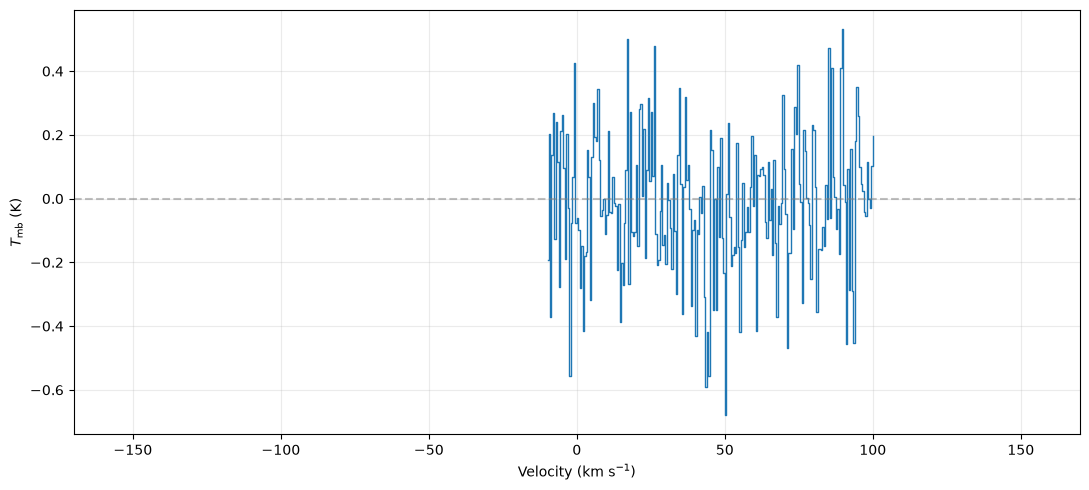

In [200]:
results_dir = Path(
    "/Users/kyriakos.trakakis/Downloads/MOPRA_HiGAL/Full_Mopra"
)
spectra_base = results_dir / "New_Mopra_spectra"

spectrum_file = (
    Path(spectra_base)
    / "G250-260"
    / "13CO_HIGALBM257.9276-0.2040_spec.fits"
)

velocity, Tmb = inspect_spectrum(
    spectrum_file,
    vmin=-170,
    vmax=170
)

In [7]:
df12 = pd.read_csv("Mopra_HiGal_fits_parameters_subtracting_12CO.txt", sep="\t")
df13 = pd.read_csv("Mopra_HiGal_fits_parameters_subtracting_13CO.txt", sep="\t")
df18 = pd.read_csv("Mopra_HiGal_fits_parameters_subtracting_C18O.txt", sep="\t")

In [8]:
## Bring the catalogues into a human form

component_columns = {
    "Amplitudes (K)": "Amplitude",
    "Mean Velocities (km/s)": "Velocity",
    "Widths (km/s)": "Width"
}

columns = [
    "Number",
    "Object Name",
    "Molecule Type",
    "Num Components",
    "HiGAL VLSR (km/s)",
    "Amplitude_1",
    "Velocity_1",
    "Width_1",
    "Amplitude_2",
    "Velocity_2",
    "Width_2",
    "Amplitude_3",
    "Velocity_3",
    "Width_3"
]


def expand_components(df):

    df = df.copy()

    # Split the Gaussian parameters for THIS catalogue
    for old_col, new_col in component_columns.items():

        split_values = (
            df[old_col]
            .astype("string")
            .str.split(",", expand=True)
        )

        for i in range(3):

            df[f"{new_col}_{i+1}"] = (
                pd.to_numeric(
                    split_values[i].str.strip(),
                    errors="coerce"
                ).astype("float64")
                if i in split_values.columns
                else np.nan
            )

    # Remove original comma-separated columns
    df = df.drop(columns=list(component_columns.keys()))

    # Arrange columns
    other_columns = [
        col for col in df.columns if col not in columns
    ]

    df = df[columns + other_columns]

    return df


# Process each catalogue independently
df12 = expand_components(df12)
df13 = expand_components(df13)
df18 = expand_components(df18)

display(df12.head())
display(df13.head())
display(df18.head())

,Number,Object Name,Molecule Type,Num Components,HiGAL VLSR (km/s),Amplitude_1,Velocity_1,Width_1,Amplitude_2,Velocity_2,Width_2,Amplitude_3,Velocity_3,Width_3
0,1,HIGALBM250.0376-0.9942,12CO,1,104.7,2.389,14.782,0.890,NaN,NaN,NaN,NaN,NaN,NaN
1,2,HIGALBM250.2274-0.0369,12CO,1,51.7,7.251,51.831,1.051,NaN,NaN,NaN,NaN,NaN,NaN
2,3,HIGALBM250.2784-0.9892,12CO,1,13.9,2.031,67.486,1.090,NaN,NaN,NaN,NaN,NaN,NaN
3,4,HIGALBM250.3619-0.9804,12CO,1,13.0,3.361,65.189,0.815,NaN,NaN,NaN,NaN,NaN,NaN
4,5,HIGALBM250.4039-0.9605,12CO,1,66.6,1.332,65.952,1.093,NaN,NaN,NaN,NaN,NaN,NaN


,Number,Object Name,Molecule Type,Num Components,HiGAL VLSR (km/s),Amplitude_1,Velocity_1,Width_1,Amplitude_2,Velocity_2,Width_2,Amplitude_3,Velocity_3,Width_3
0,2,HIGALBM250.2274-0.0369,13CO,1,51.7,1.679,51.878,0.816,NaN,NaN,NaN,NaN,NaN,NaN
1,4,HIGALBM250.3619-0.9804,13CO,1,13.0,0.923,64.922,0.661,NaN,NaN,NaN,NaN,NaN,NaN
2,6,HIGALBM250.4444-0.9467,13CO,1,12.6,0.468,92.775,0.608,NaN,NaN,NaN,NaN,NaN,NaN
3,9,HIGALBM250.5921-0.6483,13CO,1,78.6,0.525,78.325,0.829,NaN,NaN,NaN,NaN,NaN,NaN
4,10,HIGALBM250.5992-0.6366,13CO,1,78.6,0.696,78.723,0.566,NaN,NaN,NaN,NaN,NaN,NaN


,Number,Object Name,Molecule Type,Num Components,HiGAL VLSR (km/s),Amplitude_1,Velocity_1,Width_1,Amplitude_2,Velocity_2,Width_2,Amplitude_3,Velocity_3,Width_3
0,9,HIGALBM250.5921-0.6483,C18O,1,78.6,0.604,50.746,0.454,NaN,NaN,NaN,NaN,NaN,NaN
1,44,HIGALBM253.3371-0.5035,C18O,1,34.1,0.734,53.615,0.380,NaN,NaN,NaN,NaN,NaN,NaN
2,74,HIGALBM253.5176-0.2561,C18O,1,35.4,0.714,35.998,0.620,NaN,NaN,NaN,NaN,NaN,NaN
3,75,HIGALBM253.5215-0.2403,C18O,1,35.4,0.676,36.122,0.630,NaN,NaN,NaN,NaN,NaN,NaN
4,76,HIGALBM253.5248-0.2631,C18O,1,35.4,0.587,35.992,0.551,NaN,NaN,NaN,NaN,NaN,NaN


In [9]:
df13.head(12)

,Number,Object Name,Molecule Type,Num Components,HiGAL VLSR (km/s),Amplitude_1,Velocity_1,Width_1,Amplitude_2,Velocity_2,Width_2,Amplitude_3,Velocity_3,Width_3
0,2,HIGALBM250.2274-0.0369,13CO,1,51.7,1.679,51.878,0.816,NaN,NaN,NaN,NaN,NaN,NaN
1,4,HIGALBM250.3619-0.9804,13CO,1,13.0,0.923,64.922,0.661,NaN,NaN,NaN,NaN,NaN,NaN
2,6,HIGALBM250.4444-0.9467,13CO,1,12.6,0.468,92.775,0.608,NaN,NaN,NaN,NaN,NaN,NaN
3,9,HIGALBM250.5921-0.6483,13CO,1,78.6,0.525,78.325,0.829,NaN,NaN,NaN,NaN,NaN,NaN
4,10,HIGALBM250.5992-0.6366,13CO,1,78.6,0.696,78.723,0.566,NaN,NaN,NaN,NaN,NaN,NaN
5,11,HIGALBM250.6065-0.6419,13CO,1,78.6,0.669,78.690,0.625,NaN,NaN,NaN,NaN,NaN,NaN
6,12,HIGALBM250.6705-0.8158,13CO,1,-14.6,0.383,-5.467,1.049,NaN,NaN,NaN,NaN,NaN,NaN
7,14,HIGALBM251.0678-0.9813,13CO,1,9.9,2.316,9.604,0.722,NaN,NaN,NaN,NaN,NaN,NaN
8,15,HIGALBM251.0731-0.9974,13CO,1,9.9,2.693,9.527,0.697,NaN,NaN,NaN,NaN,NaN,NaN
9,16,HIGALBM251.0819-0.9882,13CO,1,9.9,2.285,9.454,0.618,NaN,NaN,NaN,NaN,NaN,NaN


In [10]:
df.to_csv('Mopra_HiGal_fits_parameters_subtracting_C18O.csv', index = False)

In [11]:
## FU-SION HA!!


THRESHOLD = 5.0


def merge_gaussians(components):
    """
    Merge Gaussian components using integrated-intensity weights
    for velocity and width, while preserving the amplitude of
    the strongest component.

    Each component is (amplitude, velocity, sigma).
    Returns (amplitude, velocity, sigma).
    """
    components = np.asarray(components, dtype=float)

    A = components[:, 0]
    V = components[:, 1]
    sigma = components[:, 2]

    # Integrated intensities
    I = A * sigma * np.sqrt(2 * np.pi)
    I_total = np.sum(I)

    if I_total <= 0:
        raise ValueError("Non-positive total integrated intensity")

    # Intensity-weighted mean velocity
    V_merged = np.sum(I * V) / I_total

    # Moment-matched width
    variance = np.sum(
        I * (sigma**2 + (V - V_merged)**2)
    ) / I_total

    sigma_merged = np.sqrt(variance)

    # Preserve amplitude of strongest component
    A_merged = np.max(A)

    return (A_merged, V_merged, sigma_merged)


def merge_row(row, threshold=5.0):

    n = int(row["Num Components"])

    components = [
        (
            row[f"Amplitude_{i}"],
            row[f"Velocity_{i}"],
            row[f"Width_{i}"]
        )
        for i in range(1, n + 1)
    ]

    if not all(
        np.all(np.isfinite(c)) and c[0] > 0 and c[2] > 0
        for c in components
    ):
        raise ValueError("Invalid Gaussian parameters")

    # Start with each component as its own group
    groups = [[i] for i in range(n)]

    if n > 1:

        velocities = np.array([c[1] for c in components])

        # Pairwise velocity distances
        distances = np.abs(
            velocities[:, None] - velocities[None, :]
        )

        # Find connected groups under the 5 km/s criterion
        # (transitive merging: 20,24,28 becomes one group)
        for i in range(n):
            for j in range(i + 1, n):

                if distances[i, j] < threshold:

                    group_i = next(g for g in groups if i in g)
                    group_j = next(g for g in groups if j in g)

                    if group_i is not group_j:
                        merged_group = group_i + group_j
                        groups.remove(group_i)
                        groups.remove(group_j)
                        groups.append(merged_group)

    # Merge each group independently
    merged_components = []

    for group in groups:

        if len(group) == 1:
            merged_components.append(components[group[0]])
        else:
            merged_components.append(
                merge_gaussians([components[i] for i in group])
            )

    # Sort resulting components by velocity
    merged_components.sort(key=lambda c: c[1])

    result = {
        "Num Components Merged": len(merged_components),
        "Was Merged": len(merged_components) < n,
        "Merge Groups": ", ".join(
            "+".join(str(i + 1) for i in sorted(g))
            for g in sorted(groups, key=lambda g: min(g))
        )
    }

    for i in range(1, 4):

        if i <= len(merged_components):
            A, V, sigma = merged_components[i - 1]
        else:
            A, V, sigma = np.nan, np.nan, np.nan

        result[f"Amplitude_merged_{i}"] = A
        result[f"Velocity_merged_{i}"] = V
        result[f"Width_merged_{i}"] = sigma

    return pd.Series(result)


# Apply to the full catalogue
merged_df_12 = df12.copy()

merge_results_12 = merged_df_12.apply(merge_row, axis=1)

merged_df_12 = pd.concat(
    [merged_df_12, merge_results_12],
    axis=1
)

merged_df_13 = df13.copy()

merge_results_13 = merged_df_13.apply(merge_row, axis=1)

merged_df_13 = pd.concat(
    [merged_df_13, merge_results_13],
    axis=1
)

merged_df_18 = df18.copy()

merge_results_18 = merged_df_18.apply(merge_row, axis=1)

merged_df_18 = pd.concat(
    [merged_df_18, merge_results_18],
    axis=1
)

In [111]:
merged_df = merged_df_12

print("Original component counts:")
print(merged_df["Num Components"].value_counts().sort_index())

print("\nAfter merging:")
print(
    merged_df["Num Components Merged"]
    .value_counts()
    .sort_index()
)

print("\nNumber of spectra affected:")
print(merged_df["Was Merged"].sum())

print("\nTransitions:")
print(
    pd.crosstab(
        merged_df["Num Components"],
        merged_df["Num Components Merged"],
        rownames=["Original"],
        colnames=["After merging"]
    )
)

Original component counts:
Num Components
1     5130
2     9879
3    19405
Name: count, dtype: int64

After merging:
Num Components Merged
1     6291
2    11707
3    16416
Name: count, dtype: int64

Number of spectra affected:
3981

Transitions:
After merging     1     2      3
Original                        
1              5130     0      0
2               992  8887      0
3               169  2820  16416


In [13]:
display(
    merged_df.loc[
        merged_df["Was Merged"],
        [
            "Object Name",
            "Num Components",
            "Num Components Merged",
            "Merge Groups",
            "Velocity_1",
            "Velocity_2",
            "Velocity_3",
            "Velocity_merged_1",
            "Velocity_merged_2",
            "Velocity_merged_3"
        ]
    ]
)

,Object Name,Num Components,Num Components Merged,Merge Groups,Velocity_1,Velocity_2,Velocity_3,Velocity_merged_1,Velocity_merged_2,Velocity_merged_3
106,HIGALBM254.1465-0.1557,2,1,1+2,31.248,35.650,NaN,33.207065,NaN,NaN
178,HIGALBM257.9484-0.5126,2,1,1+2,48.600,51.875,NaN,50.851428,NaN,NaN
260,HIGALBM261.0417+0.0981,2,1,1+2,6.969,10.170,NaN,9.661260,NaN,NaN
364,HIGALBM263.0327-0.2354,2,1,1+2,6.999,10.848,NaN,9.593136,NaN,NaN
366,HIGALBM263.0480-0.0203,2,1,1+2,2.923,6.943,NaN,3.646519,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...
30383,HIGALBM354.8133+0.9751,3,2,"1, 2+3",-22.146,2.118,2.612,-22.146000,2.162852,NaN
30400,HIGALBM354.8501-0.0019,3,2,"1+2, 3",-18.188,-13.885,10.699,-17.018084,10.699000,NaN
30418,HIGALBM354.9054-0.5346,3,2,"1+2, 3",-4.014,0.698,6.095,-3.443715,6.095000,NaN
30444,HIGALBM354.9576+0.7616,2,1,1+2,-20.053,-18.144,NaN,-18.496100,NaN,NaN


In [14]:
merged_df[(merged_df['Num Components'] == 3) & (merged_df['Num Components Merged'] == 1)]

,Number,Object Name,Molecule Type,Num Components,HiGAL VLSR (km/s),Amplitude_1,Velocity_1,Width_1,Amplitude_2,Velocity_2,...,Merge Groups,Amplitude_merged_1,Velocity_merged_1,Width_merged_1,Amplitude_merged_2,Velocity_merged_2,Width_merged_2,Amplitude_merged_3,Velocity_merged_3,Width_merged_3
511,398,HIGALBM264.2329-0.1278,13CO,3,NaN,0.415,3.955,0.712,2.825,8.580,...,1+2+3,2.825,9.440897,2.687542,NaN,NaN,NaN,NaN,NaN,NaN
581,479,HIGALBM266.2790-0.4964,13CO,3,NaN,1.794,3.974,0.737,1.936,6.660,...,1+2+3,1.936,6.595716,2.240300,NaN,NaN,NaN,NaN,NaN,NaN
935,850,HIGALBM268.4859-0.5288,13CO,3,NaN,2.060,2.440,0.675,0.724,4.630,...,1+2+3,2.357,6.601589,3.438356,NaN,NaN,NaN,NaN,NaN,NaN
2601,1569,HIGALBM286.3552-0.2651,13CO,3,-22.6,1.229,-24.658,0.898,5.260,-22.681,...,1+2+3,5.260,-22.891621,1.389511,NaN,NaN,NaN,NaN,NaN,NaN
3665,371,HIGALBM291.2567-0.7664,13CO,3,-24.6,1.349,-27.589,0.725,12.398,-23.923,...,1+2+3,12.398,-23.678580,2.011581,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
29199,1689,HIGALBM352.6543-0.6292,13CO,3,-5.7,1.315,-10.174,0.636,0.432,-8.912,...,1+2+3,1.552,-8.144700,4.877954,NaN,NaN,NaN,NaN,NaN,NaN
29363,1854,HIGALBM352.9652+0.6368,13CO,3,-3.4,2.302,-3.403,1.424,1.051,1.366,...,1+2+3,2.302,-1.093289,3.459718,NaN,NaN,NaN,NaN,NaN,NaN
29463,1954,HIGALBM353.0712+0.5024,13CO,3,-3.7,1.099,-5.563,0.958,6.816,-3.206,...,1+2+3,6.816,-3.144523,1.480396,NaN,NaN,NaN,NaN,NaN,NaN
29560,2052,HIGALBM353.1944+0.8326,13CO,3,-5.1,0.857,-9.416,1.072,1.023,-6.383,...,1+2+3,1.509,-6.605717,3.667609,NaN,NaN,NaN,NaN,NaN,NaN


In [18]:
fit_results_re = plot_spectra_re(
    higal_df,
    spectra_dir,
    output_dir = "Iterative_fits",
    output_file = "Mopra_HiGal_re_fits_parameters.txt",
    vmin=-170,
    vmax=170,
    velocity_col="VLSR",
    max_components=3,
    noise_threshold=3.5,
    velocity_unit="km/s",
    max_sigma = 10.5
):

Number of spectra found: 2986

Processing: 13CO_HIGALBM350.0011+0.4307_spec.fits
Successfully fitted 2 components.

Processing: 13CO_HIGALBM350.0013+0.0763_spec.fits
Successfully fitted 3 components.

Processing: 13CO_HIGALBM350.0037-0.5531_spec.fits
Successfully fitted 3 components.

Processing: 13CO_HIGALBM350.0057-0.5372_spec.fits
Successfully fitted 3 components.

Processing: 13CO_HIGALBM350.0109-0.8250_spec.fits
Successfully fitted 3 components.

Processing: 13CO_HIGALBM350.0127-0.8489_spec.fits
Successfully fitted 1 components.

Processing: 13CO_HIGALBM350.0145+0.4223_spec.fits
Successfully fitted 2 components.

Processing: 13CO_HIGALBM350.0181-0.5200_spec.fits
Successfully fitted 3 components.

Processing: 13CO_HIGALBM350.0188-0.5616_spec.fits
Successfully fitted 3 components.

Processing: 13CO_HIGALBM350.0204-0.7974_spec.fits
Successfully fitted 2 components.

Processing: 13CO_HIGALBM350.0216-0.3961_spec.fits
Successfully fitted 1 components.

Processing: 13CO_HIGALBM350.0224-0

In [15]:
def prepare(df, suffix, use_merged=True):

    count_col = (
        "Num Components Merged"
        if use_merged
        else "Num Components"
    )

    result = df[["Object Name", count_col]].copy()

    result["Object Name"] = (
        result["Object Name"].astype(str).str.strip()
    )

    result[count_col] = pd.to_numeric(
        result[count_col], errors="coerce"
    )

    if result["Object Name"].duplicated().any():
        raise ValueError(
            f"Duplicate clump names in {suffix} catalogue"
        )

    return result.rename(
        columns={count_col: f"N_{suffix}"}
    )

# If you ever feel like doing the originals
#d12 = prepare(df12, "12")
#d13 = prepare(df13, "13")
#d18 = prepare(df18, "18")

d12 = prepare(merged_df_12, "12")
d13 = prepare(merged_df_13, "13")
d18 = prepare(merged_df_18, "18")

# Outer join preserves clumps present in any catalogue
comparison = (
    d12.merge(d13, on="Object Name", how="outer")
       .merge(d18, on="Object Name", how="outer")
)

# Flags for exactly one component
for mol in ["12", "13", "18"]:
    comparison[f"Single_{mol}"] = comparison[f"N_{mol}"].eq(1)

In [16]:
print("Single-component clumps by molecule:")

for mol in ["12", "13", "18"]:
    print(
        f"{mol}CO: {comparison[f'Single_{mol}'].sum()}"
    )

print("\nSingle-component overlaps:")

print(
    "Single in all three:",
    (
        comparison["Single_12"]
        & comparison["Single_13"]
        & comparison["Single_18"]
    ).sum()
)

print(
    "Single in 12 and 13:",
    (
        comparison["Single_12"]
        & comparison["Single_13"]
    ).sum()
)

print(
    "Single in 13 and 18:",
    (
        comparison["Single_13"]
        & comparison["Single_18"]
    ).sum()
)

print(
    "Single in 12 and 18:",
    (
        comparison["Single_12"]
        & comparison["Single_18"]
    ).sum()
)

Single-component clumps by molecule:
12CO: 6291
13CO: 12967
18CO: 10078

Single-component overlaps:
Single in all three: 672
Single in 12 and 13: 3719
Single in 13 and 18: 3009
Single in 12 and 18: 1041


In [17]:
# Single in C18O, but not single in either 12CO or 13CO
unique_18 = comparison[
    comparison["Single_18"]
    & ~comparison["Single_12"]
    & ~comparison["Single_13"]
].copy()

# Single in 13CO, but not single in 12CO
unique_13 = comparison[
    comparison["Single_13"]
    & ~comparison["Single_12"]
].copy()

# Single in 12CO, but not single in 13CO
unique_12 = comparison[
    comparison["Single_12"]
    & ~comparison["Single_13"]
].copy()

print("Single in C18O, not single in 12CO or 13CO:", len(unique_18))
print("Single in 13CO, not single in 12CO:", len(unique_13))
print("Single in 12CO, not single in 13CO:", len(unique_12))

display(unique_18)
display(unique_13)
display(unique_12)

Single in C18O, not single in 12CO or 13CO: 6700
Single in 13CO, not single in 12CO: 9248
Single in 12CO, not single in 13CO: 2572


,Object Name,N_12,N_13,N_18,Single_12,Single_13,Single_18
105,HIGALBM253.7847-0.5889,2.0,NaN,1.0,False,False,True
127,HIGALBM253.9528-0.5698,2.0,NaN,1.0,False,False,True
217,HIGALBM254.5980-0.1869,NaN,NaN,1.0,False,False,True
229,HIGALBM255.6958-0.5103,NaN,NaN,1.0,False,False,True
246,HIGALBM256.9858-0.8917,NaN,NaN,1.0,False,False,True
...,...,...,...,...,...,...,...
34461,HIGALBM354.9389+0.3324,3.0,3.0,1.0,False,False,True
34469,HIGALBM354.9532-0.6595,2.0,2.0,1.0,False,False,True
34479,HIGALBM354.9630-0.3016,2.0,NaN,1.0,False,False,True
34486,HIGALBM354.9738+0.5569,3.0,2.0,1.0,False,False,True


,Object Name,N_12,N_13,N_18,Single_12,Single_13,Single_18
10,HIGALBM250.6065-0.6419,2.0,1.0,NaN,False,True,False
11,HIGALBM250.6705-0.8158,NaN,1.0,NaN,False,True,False
59,HIGALBM253.4759-0.2586,3.0,1.0,NaN,False,True,False
99,HIGALBM253.7221-0.8648,2.0,1.0,NaN,False,True,False
106,HIGALBM253.8003-0.4934,2.0,1.0,NaN,False,True,False
...,...,...,...,...,...,...,...
34478,HIGALBM354.9625-0.5763,2.0,1.0,1.0,False,True,True
34487,HIGALBM354.9763+0.4104,3.0,1.0,NaN,False,True,False
34488,HIGALBM354.9785-0.2168,3.0,1.0,NaN,False,True,False
34490,HIGALBM354.9875+0.2601,3.0,1.0,NaN,False,True,False


,Object Name,N_12,N_13,N_18,Single_12,Single_13,Single_18
0,HIGALBM250.0376-0.9942,1.0,NaN,NaN,True,False,False
2,HIGALBM250.2784-0.9892,1.0,NaN,NaN,True,False,False
4,HIGALBM250.4039-0.9605,1.0,NaN,NaN,True,False,False
6,HIGALBM250.5513-0.8419,1.0,NaN,NaN,True,False,False
7,HIGALBM250.5699-0.9786,1.0,NaN,NaN,True,False,False
...,...,...,...,...,...,...,...
34245,HIGALBM354.5153+0.0672,1.0,2.0,NaN,True,False,False
34274,HIGALBM354.5778-0.3745,1.0,NaN,NaN,True,False,False
34298,HIGALBM354.6269-0.6223,1.0,2.0,1.0,True,False,True
34444,HIGALBM354.9028-0.8314,1.0,2.0,1.0,True,False,True


In [18]:
def describe_comparison(subset, other_col):
    return pd.Series({
        "No catalogue entry": subset[other_col].isna().sum(),
        "One component": subset[other_col].eq(1).sum(),
        "Multiple components": subset[other_col].gt(1).sum()
    })

print("For unique C18O singles, 12CO status:")
print(describe_comparison(unique_18, "N_12"))

print("\nFor unique C18O singles, 13CO status:")
print(describe_comparison(unique_18, "N_13"))

print("\nFor unique 13CO singles, 12CO status:")
print(describe_comparison(unique_13, "N_12"))

print("\nFor unique 12CO singles, 13CO status:")
print(describe_comparison(unique_12, "N_13"))

For unique C18O singles, 12CO status:
No catalogue entry       29
One component             0
Multiple components    6671
dtype: int64

For unique C18O singles, 13CO status:
No catalogue entry      170
One component             0
Multiple components    6530
dtype: int64

For unique 13CO singles, 12CO status:
No catalogue entry       41
One component             0
Multiple components    9207
dtype: int64

For unique 12CO singles, 13CO status:
No catalogue entry     1850
One component             0
Multiple components     722
dtype: int64


In [19]:
# Include all clumps appearing in at least one catalogue
comparison = (
    d18.merge(d13, on="Object Name", how="outer")
       .merge(d12, on="Object Name", how="outer")
)

# ------------------------------------------
# Hierarchical selection: 18 -> 13 -> 12
# ------------------------------------------

single_18 = comparison[
    comparison["N_18"].eq(1)
].copy()

single_13 = comparison[
    ~comparison["N_18"].eq(1)
    & comparison["N_13"].eq(1)
].copy()

single_12 = comparison[
    ~comparison["N_18"].eq(1)
    & ~comparison["N_13"].eq(1)
    & comparison["N_12"].eq(1)
].copy()

unassigned = comparison[
    ~comparison["N_18"].eq(1)
    & ~comparison["N_13"].eq(1)
    & ~comparison["N_12"].eq(1)
].copy()

# ------------------------------------------
# Results
# ------------------------------------------

print(f"Total unique clumps: {len(comparison)}")

print(f"Single component in C18O: {len(single_18)}")
print(f"Single component in 13CO (not C18O): {len(single_13)}")
print(f"Single component in 12CO (not C18O or 13CO): {len(single_12)}")
print(f"No single component in any tracer: {len(unassigned)}")

print("\nCheck total:")
print(
    len(single_18)
    + len(single_13)
    + len(single_12)
    + len(unassigned)
)

# Display clumps in each category
display(single_18)
display(single_13)
display(single_12)
display(unassigned)

Total unique clumps: 34494
Single component in C18O: 10078
Single component in 13CO (not C18O): 9958
Single component in 12CO (not C18O or 13CO): 2203
No single component in any tracer: 12255

Check total:
34494


,Object Name,N_18,N_13,N_12
8,HIGALBM250.5921-0.6483,1.0,1.0,1.0
37,HIGALBM253.3371-0.5035,1.0,NaN,1.0
67,HIGALBM253.5176-0.2561,1.0,1.0,1.0
68,HIGALBM253.5215-0.2403,1.0,1.0,1.0
69,HIGALBM253.5248-0.2631,1.0,1.0,1.0
...,...,...,...,...
34479,HIGALBM354.9630-0.3016,1.0,NaN,2.0
34480,HIGALBM354.9666-0.5012,1.0,1.0,1.0
34483,HIGALBM354.9724-0.5340,1.0,1.0,1.0
34486,HIGALBM354.9738+0.5569,1.0,2.0,3.0


,Object Name,N_18,N_13,N_12
1,HIGALBM250.2274-0.0369,NaN,1.0,1.0
3,HIGALBM250.3619-0.9804,NaN,1.0,1.0
5,HIGALBM250.4444-0.9467,NaN,1.0,1.0
9,HIGALBM250.5992-0.6366,NaN,1.0,1.0
10,HIGALBM250.6065-0.6419,NaN,1.0,2.0
...,...,...,...,...
34472,HIGALBM354.9576+0.7616,NaN,1.0,3.0
34487,HIGALBM354.9763+0.4104,NaN,1.0,3.0
34488,HIGALBM354.9785-0.2168,NaN,1.0,3.0
34490,HIGALBM354.9875+0.2601,NaN,1.0,3.0


,Object Name,N_18,N_13,N_12
0,HIGALBM250.0376-0.9942,NaN,NaN,1.0
2,HIGALBM250.2784-0.9892,NaN,NaN,1.0
4,HIGALBM250.4039-0.9605,NaN,NaN,1.0
6,HIGALBM250.5513-0.8419,NaN,NaN,1.0
7,HIGALBM250.5699-0.9786,NaN,NaN,1.0
...,...,...,...,...
34197,HIGALBM354.4092-0.9830,NaN,NaN,1.0
34228,HIGALBM354.4605+0.0869,NaN,3.0,1.0
34234,HIGALBM354.4784+0.0844,NaN,3.0,1.0
34245,HIGALBM354.5153+0.0672,NaN,2.0,1.0


,Object Name,N_18,N_13,N_12
47,HIGALBM253.4353-0.1052,NaN,2.0,2.0
104,HIGALBM253.7694-0.7657,NaN,NaN,2.0
107,HIGALBM253.8174-0.6031,NaN,NaN,2.0
119,HIGALBM253.9046-0.6314,NaN,2.0,2.0
128,HIGALBM253.9699-0.7205,NaN,NaN,2.0
...,...,...,...,...
34482,HIGALBM354.9708+0.1938,NaN,3.0,3.0
34484,HIGALBM354.9725-0.7208,2.0,2.0,2.0
34485,HIGALBM354.9737+0.6769,NaN,3.0,3.0
34492,HIGALBM354.9928+0.6494,NaN,2.0,3.0


In [20]:
# ------------------------------------------
# Hierarchical selection: 13 -> 12
# ------------------------------------------


single_13 = comparison[ comparison["N_13"].eq(1)].copy()

single_12 = comparison[ ~comparison["N_13"].eq(1)& comparison["N_12"].eq(1)].copy()

unassigned = comparison[~comparison["N_13"].eq(1) & ~comparison["N_12"].eq(1) ].copy()

# ------------------------------------------
# Results
# ------------------------------------------

print(f"Total unique clumps: {len(comparison)}")


print(f"Single component in 13CO : {len(single_13)}")
print(f"Single component in 12CO (not 13CO): {len(single_12)}")
print(f"No single component in 12 or 13: {len(unassigned)}")

print("\nCheck total:")
print(
     len(single_13)
    + len(single_12)
    + len(unassigned)
)

# Display clumps in each category
display(single_13)
display(single_12)
display(unassigned)

Total unique clumps: 34494
Single component in 13CO : 12967
Single component in 12CO (not 13CO): 2572
No single component in 12 or 13: 18955

Check total:
34494


,Object Name,N_18,N_13,N_12
1,HIGALBM250.2274-0.0369,NaN,1.0,1.0
3,HIGALBM250.3619-0.9804,NaN,1.0,1.0
5,HIGALBM250.4444-0.9467,NaN,1.0,1.0
8,HIGALBM250.5921-0.6483,1.0,1.0,1.0
9,HIGALBM250.5992-0.6366,NaN,1.0,1.0
...,...,...,...,...
34483,HIGALBM354.9724-0.5340,1.0,1.0,1.0
34487,HIGALBM354.9763+0.4104,NaN,1.0,3.0
34488,HIGALBM354.9785-0.2168,NaN,1.0,3.0
34490,HIGALBM354.9875+0.2601,NaN,1.0,3.0


,Object Name,N_18,N_13,N_12
0,HIGALBM250.0376-0.9942,NaN,NaN,1.0
2,HIGALBM250.2784-0.9892,NaN,NaN,1.0
4,HIGALBM250.4039-0.9605,NaN,NaN,1.0
6,HIGALBM250.5513-0.8419,NaN,NaN,1.0
7,HIGALBM250.5699-0.9786,NaN,NaN,1.0
...,...,...,...,...
34245,HIGALBM354.5153+0.0672,NaN,2.0,1.0
34274,HIGALBM354.5778-0.3745,NaN,NaN,1.0
34298,HIGALBM354.6269-0.6223,1.0,2.0,1.0
34444,HIGALBM354.9028-0.8314,1.0,2.0,1.0


,Object Name,N_18,N_13,N_12
47,HIGALBM253.4353-0.1052,NaN,2.0,2.0
104,HIGALBM253.7694-0.7657,NaN,NaN,2.0
105,HIGALBM253.7847-0.5889,1.0,NaN,2.0
107,HIGALBM253.8174-0.6031,NaN,NaN,2.0
119,HIGALBM253.9046-0.6314,NaN,2.0,2.0
...,...,...,...,...
34485,HIGALBM354.9737+0.6769,NaN,3.0,3.0
34486,HIGALBM354.9738+0.5569,1.0,2.0,3.0
34489,HIGALBM354.9832+0.5619,1.0,2.0,3.0
34492,HIGALBM354.9928+0.6494,NaN,2.0,3.0


In [21]:
# ------------------------------------------
# Single components in 12
# ------------------------------------------

single_12 = comparison[comparison["N_12"].eq(1)].copy()

unassigned = comparison[~comparison["N_12"].eq(1) ].copy()

# ------------------------------------------
# Results
# ------------------------------------------

print(f"Total unique clumps: {len(comparison)}")


print(f"Single component in 12CO: {len(single_12)}")
print(f"No single component in 12: {len(unassigned)}")

print("\nCheck total:")
print(
      len(single_12)
    + len(unassigned)
)

# Display clumps in each category
display(single_12)
display(unassigned)

Total unique clumps: 34494
Single component in 12CO: 6291
No single component in 12: 28203

Check total:
34494


,Object Name,N_18,N_13,N_12
0,HIGALBM250.0376-0.9942,NaN,NaN,1.0
1,HIGALBM250.2274-0.0369,NaN,1.0,1.0
2,HIGALBM250.2784-0.9892,NaN,NaN,1.0
3,HIGALBM250.3619-0.9804,NaN,1.0,1.0
4,HIGALBM250.4039-0.9605,NaN,NaN,1.0
...,...,...,...,...
34436,HIGALBM354.8746-0.8591,NaN,1.0,1.0
34444,HIGALBM354.9028-0.8314,1.0,2.0,1.0
34475,HIGALBM354.9596-0.7115,1.0,2.0,1.0
34480,HIGALBM354.9666-0.5012,1.0,1.0,1.0


,Object Name,N_18,N_13,N_12
10,HIGALBM250.6065-0.6419,NaN,1.0,2.0
11,HIGALBM250.6705-0.8158,NaN,1.0,NaN
47,HIGALBM253.4353-0.1052,NaN,2.0,2.0
59,HIGALBM253.4759-0.2586,NaN,1.0,3.0
99,HIGALBM253.7221-0.8648,NaN,1.0,2.0
...,...,...,...,...
34489,HIGALBM354.9832+0.5619,1.0,2.0,3.0
34490,HIGALBM354.9875+0.2601,NaN,1.0,3.0
34491,HIGALBM354.9920-0.1962,NaN,1.0,2.0
34492,HIGALBM354.9928+0.6494,NaN,2.0,3.0


In [37]:
higal_df = higal_df[['DESIGNATION', 'GLON', 'GLAT', 'DIST', 'VLSR', 'R_GAL', 'MASS', 'DMASS', 'TEMP', 'DTEMP', 'L_BOL']]

# Create a master catalogue

In [208]:
# --------------------------------------------------
# 1. Start with the 34,494 clumps in comparison
# --------------------------------------------------

master_df = comparison.copy()

# --------------------------------------------------
# 2. Prepare the Hi-GAL physical properties
# --------------------------------------------------

higal_properties = higal_df.copy()

# Hi-GAL uses DESIGNATION, fitting catalogues use Object Name
higal_properties = higal_properties.rename(
    columns={"DESIGNATION": "Object Name"}
)

# Standardize clump identifiers
master_df["Object Name"] = (
    master_df["Object Name"].astype(str).str.strip()
)

higal_properties["Object Name"] = (
    higal_properties["Object Name"].astype(str).str.strip()
)

# Ensure one Hi-GAL row per clump
if higal_properties["Object Name"].duplicated().any():
    raise ValueError("Duplicate designations in Hi-GAL catalogue")

# Add all Hi-GAL physical properties
master_df = master_df.merge(
    higal_properties,
    on="Object Name",
    how="left",
    validate="one_to_one"
)

# --------------------------------------------------
# 3. Add Gaussian fitting parameters for each tracer
# --------------------------------------------------

molecular_catalogues = {
    "12CO": merged_df_12,
    "13CO": merged_df_13,
    "C18O": merged_df_18
}

for molecule, df in molecular_catalogues.items():

    molecular_df = df.copy()

    molecular_df["Object Name"] = (
        molecular_df["Object Name"].astype(str).str.strip()
    )

    # Remove columns already available from comparison
    # or Hi-GAL to avoid duplication
    columns_to_drop = [
        "Number",
        "Molecule Type",
        "HiGAL VLSR (km/s)"
    ]

    molecular_df = molecular_df.drop(
        columns=columns_to_drop,
        errors="ignore"
    )

    # Give every molecular parameter a unique suffix
    molecular_df = molecular_df.rename(
        columns={
            col: f"{col}_{molecule}"
            for col in molecular_df.columns
            if col != "Object Name"
        }
    )

    # Merge into master catalogue
    master_df = master_df.merge(
        molecular_df,
        on="Object Name",
        how="left",
        validate="one_to_one"
    )

# --------------------------------------------------
# 4. Check catalogue
# --------------------------------------------------

print("Number of clumps:", len(master_df))
print("Number of columns:", len(master_df.columns))

print("\nMolecular component counts:")
print(
    master_df[
        ["N_12", "N_13", "N_18"]
    ].notna().sum()
)

display(master_df.head())

Number of clumps: 34494
Number of columns: 80

Molecular component counts:
N_12    34414
N_13    30463
N_18    11946
dtype: int64


,Object Name,N_18,N_13,N_12,GLON,GLAT,DIST,VLSR,R_GAL,MASS,...,Merge Groups_C18O,Amplitude_merged_1_C18O,Velocity_merged_1_C18O,Width_merged_1_C18O,Amplitude_merged_2_C18O,Velocity_merged_2_C18O,Width_merged_2_C18O,Amplitude_merged_3_C18O,Velocity_merged_3_C18O,Width_merged_3_C18O
0,HIGALBM250.0376-0.9942,NaN,NaN,1.0,250.037554,-0.994241,9.62,104.7,14.73,6.3,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,HIGALBM250.2274-0.0369,NaN,1.0,1.0,250.227356,-0.036858,4.43,51.7,10.69,67.5,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,HIGALBM250.2784-0.9892,NaN,NaN,1.0,250.278385,-0.989168,1.32,13.9,8.87,2.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,HIGALBM250.3619-0.9804,NaN,1.0,1.0,250.361857,-0.980392,1.24,13.0,8.83,7.7,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,HIGALBM250.4039-0.9605,NaN,NaN,1.0,250.403873,-0.960471,5.73,66.6,11.59,45.9,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [51]:
#master_df.to_csv('Mopra_Master_HiGAL_catalogue.csv', index = False)

In [209]:
master_df[master_df['VLSR'] < -170]

,Object Name,N_18,N_13,N_12,GLON,GLAT,DIST,VLSR,R_GAL,MASS,...,Merge Groups_C18O,Amplitude_merged_1_C18O,Velocity_merged_1_C18O,Width_merged_1_C18O,Amplitude_merged_2_C18O,Velocity_merged_2_C18O,Width_merged_2_C18O,Amplitude_merged_3_C18O,Velocity_merged_3_C18O,Width_merged_3_C18O
12,HIGALBM250.8842-0.6680,NaN,NaN,1.0,250.884200,-0.668021,-1.0,-999.0,-999.0,-1.5,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
17,HIGALBM251.4079-0.1814,NaN,NaN,1.0,251.407900,-0.181387,-1.0,-999.0,-999.0,-0.7,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
18,HIGALBM251.8226-0.3257,NaN,NaN,1.0,251.822562,-0.325718,-1.0,-999.0,-999.0,-1.1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
21,HIGALBM252.6377-0.4712,NaN,NaN,1.0,252.637699,-0.471168,-1.0,-999.0,-999.0,-2.7,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
36,HIGALBM253.2667-0.5893,NaN,NaN,1.0,253.266696,-0.589267,-1.0,-999.0,-999.0,-4.6,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
33930,HIGALBM353.6959-0.3347,NaN,2.0,3.0,353.695897,-0.334749,-1.0,-186.0,-999.0,-2.7,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
34088,HIGALBM354.1405+0.9642,NaN,NaN,1.0,354.140514,0.964165,-1.0,-999.0,-999.0,-2.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
34165,HIGALBM354.3540-0.1277,1.0,3.0,3.0,354.354004,-0.127698,-1.0,-183.9,-999.0,-16.1,...,1,0.582,-15.976,0.486,NaN,NaN,NaN,NaN,NaN,NaN
34451,HIGALBM354.9174+0.7937,NaN,3.0,3.0,354.917447,0.793744,-1.0,-999.0,-999.0,-12.5,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [210]:
master_df.columns

Index(['Object Name', 'N_18', 'N_13', 'N_12', 'GLON', 'GLAT', 'DIST', 'VLSR',
       'R_GAL', 'MASS', 'DMASS', 'TEMP', 'DTEMP', 'L_BOL',
       'Num Components_12CO', 'Amplitude_1_12CO', 'Velocity_1_12CO',
       'Width_1_12CO', 'Amplitude_2_12CO', 'Velocity_2_12CO', 'Width_2_12CO',
       'Amplitude_3_12CO', 'Velocity_3_12CO', 'Width_3_12CO',
       'Num Components Merged_12CO', 'Was Merged_12CO', 'Merge Groups_12CO',
       'Amplitude_merged_1_12CO', 'Velocity_merged_1_12CO',
       'Width_merged_1_12CO', 'Amplitude_merged_2_12CO',
       'Velocity_merged_2_12CO', 'Width_merged_2_12CO',
       'Amplitude_merged_3_12CO', 'Velocity_merged_3_12CO',
       'Width_merged_3_12CO', 'Num Components_13CO', 'Amplitude_1_13CO',
       'Velocity_1_13CO', 'Width_1_13CO', 'Amplitude_2_13CO',
       'Velocity_2_13CO', 'Width_2_13CO', 'Amplitude_3_13CO',
       'Velocity_3_13CO', 'Width_3_13CO', 'Num Components Merged_13CO',
       'Was Merged_13CO', 'Merge Groups_13CO', 'Amplitude_merged_1_13CO',
 

In [50]:
master_df[master_df['Num Components Merged_13CO'] == 1]

,Object Name,N_18,N_13,N_12,GLON,GLAT,DIST,VLSR,R_GAL,MASS,...,Merge Groups_C18O,Amplitude_merged_1_C18O,Velocity_merged_1_C18O,Width_merged_1_C18O,Amplitude_merged_2_C18O,Velocity_merged_2_C18O,Width_merged_2_C18O,Amplitude_merged_3_C18O,Velocity_merged_3_C18O,Width_merged_3_C18O
1,HIGALBM250.2274-0.0369,NaN,1.0,1.0,250.227356,-0.036858,4.43,51.7,10.69,67.5,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,HIGALBM250.3619-0.9804,NaN,1.0,1.0,250.361857,-0.980392,1.24,13.0,8.83,7.7,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,HIGALBM250.4444-0.9467,NaN,1.0,1.0,250.444432,-0.946706,1.20,12.6,8.81,2.9,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,HIGALBM250.5921-0.6483,1.0,1.0,1.0,250.592060,-0.648295,6.86,78.6,12.44,168.2,...,1,0.604,50.746,0.454,NaN,NaN,NaN,NaN,NaN,NaN
9,HIGALBM250.5992-0.6366,NaN,1.0,1.0,250.599246,-0.636588,6.86,78.6,12.43,139.2,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
34483,HIGALBM354.9724-0.5340,1.0,1.0,1.0,354.972389,-0.534024,1.67,-5.3,6.68,9.0,...,1,1.548,-5.312,1.275,NaN,NaN,NaN,NaN,NaN,NaN
34487,HIGALBM354.9763+0.4104,NaN,1.0,3.0,354.976326,0.410363,1.20,1.6,7.15,35.4,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
34488,HIGALBM354.9785-0.2168,NaN,1.0,3.0,354.978522,-0.216850,1.20,0.6,7.15,22.5,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
34490,HIGALBM354.9875+0.2601,NaN,1.0,3.0,354.987544,0.260081,1.20,5.1,7.15,59.6,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [211]:
# Canon: Single 13 components
# 1. Create an empty velocity column
master_df["Vlsr_new"] = np.nan

# 2. Assign velocities where 13CO has exactly one merged component
mask = master_df["Num Components Merged_13CO"].eq(1)

master_df.loc[mask, "Vlsr_new"] = master_df.loc[
    mask, "Velocity_merged_1_13CO"
]

# 3. Create a subset of clumps without an assigned velocity
remaining_df = master_df[master_df["Vlsr_new"].isna()].copy()

# 4. Check results
print(f"Total clumps: {len(master_df)}")
print(f"Assigned velocities: {master_df['Vlsr_new'].notna().sum()}")
print(f"Remaining clumps: {len(remaining_df)}")

Total clumps: 34494
Assigned velocities: 12967
Remaining clumps: 21527


In [212]:
remaining_df

,Object Name,N_18,N_13,N_12,GLON,GLAT,DIST,VLSR,R_GAL,MASS,...,Amplitude_merged_1_C18O,Velocity_merged_1_C18O,Width_merged_1_C18O,Amplitude_merged_2_C18O,Velocity_merged_2_C18O,Width_merged_2_C18O,Amplitude_merged_3_C18O,Velocity_merged_3_C18O,Width_merged_3_C18O,Vlsr_new
0,HIGALBM250.0376-0.9942,NaN,NaN,1.0,250.037554,-0.994241,9.62,104.7,14.73,6.3,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,HIGALBM250.2784-0.9892,NaN,NaN,1.0,250.278385,-0.989168,1.32,13.9,8.87,2.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,HIGALBM250.4039-0.9605,NaN,NaN,1.0,250.403873,-0.960471,5.73,66.6,11.59,45.9,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,HIGALBM250.5513-0.8419,NaN,NaN,1.0,250.551330,-0.841903,1.52,16.2,8.96,0.2,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,HIGALBM250.5699-0.9786,NaN,NaN,1.0,250.569904,-0.978553,1.38,14.5,8.89,2.5,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
34485,HIGALBM354.9737+0.6769,NaN,3.0,3.0,354.973700,0.676895,1.20,1.5,7.15,33.7,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
34486,HIGALBM354.9738+0.5569,1.0,2.0,3.0,354.973789,0.556864,1.20,0.4,7.15,48.3,...,0.979,0.177,0.895,NaN,NaN,NaN,NaN,NaN,NaN,NaN
34489,HIGALBM354.9832+0.5619,1.0,2.0,3.0,354.983225,0.561901,1.20,-1.1,7.15,14.1,...,0.896,0.022,0.729,NaN,NaN,NaN,NaN,NaN,NaN,NaN
34492,HIGALBM354.9928+0.6494,NaN,2.0,3.0,354.992822,0.649389,1.20,1.5,7.15,15.6,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [106]:
## Ignore

count = 0

for index, row in remaining_df.iterrows():

    amplitudes = np.array([
        row["Amplitude_merged_1_13CO"],
        row["Amplitude_merged_2_13CO"],
        row["Amplitude_merged_3_13CO"]
    ], dtype=float)

    # Remove NaNs
    amplitudes = amplitudes[np.isfinite(amplitudes)]

    if len(amplitudes) < 2:
        continue

    # Sort from highest to lowest
    amplitudes = np.sort(amplitudes)[::-1]

    max_comp = amplitudes[0]
    second_max = amplitudes[1]
    third_max = amplitudes[2] if len(amplitudes) > 2 else np.nan

    ratio = max_comp / second_max
    if ratio > 2:
        count = count + 1
    
    print(max_comp, second_max, third_max, ratio)

print(count)

0.503 0.48 nan 1.0479166666666666
0.684 0.557 nan 1.2280071813285458
1.517 1.045 nan 1.4516746411483255
0.564 0.439 nan 1.2847380410022777
1.128 0.446 nan 2.52914798206278
0.682 0.46 nan 1.482608695652174
0.935 0.59 nan 1.5847457627118646
0.668 0.454 nan 1.47136563876652
0.86 0.479 nan 1.7954070981210857
0.81 0.552 nan 1.4673913043478262
0.815 0.799 nan 1.0200250312891113
0.676 0.543 nan 1.2449355432780846
0.673 0.285 nan 2.36140350877193
1.049 0.657 nan 1.5966514459665142
0.822 0.672 nan 1.2232142857142856
0.412 0.389 nan 1.0591259640102826
0.471 0.318 nan 1.4811320754716981
0.847 0.697 nan 1.2152080344332856
0.478 0.47 nan 1.0170212765957447
1.328 0.494 nan 2.688259109311741
1.189 0.768 nan 1.5481770833333335
1.359 0.515 nan 2.6388349514563108
0.558 0.498 nan 1.1204819277108435
0.596 0.568 nan 1.0492957746478875
1.975 0.452 nan 4.369469026548672
1.055 0.455 nan 2.3186813186813184
0.735 0.61 nan 1.2049180327868851
1.264 0.519 nan 2.4354527938342967
1.057 0.552 nan 1.9148550724637678
1

In [251]:
## Also ignore

THRESHOLD = 5.0

def check_secondary_components(row, element):

    # Only consider clumps with multiple merged components
    n = row[f"Num Components Merged_{element}"]

    if pd.isna(n) or n < 2 or pd.isna(row["VLSR"]):
        return False

    components = []

    for i in range(1, int(n) + 1):

        A = row[f"Amplitude_merged_{i}_{element}"]
        V = row[f"Velocity_merged_{i}_{element}"]

        if pd.notna(A) and pd.notna(V):
            components.append((float(A), float(V)))

    if len(components) < 2:
        return False

    # Sort by amplitude, strongest first
    components.sort(key=lambda c: c[0], reverse=True)

    # Exclude the strongest component
    weaker_components = components[1:]

    # Check whether any weaker component is within 5 km/s
    return any(
        abs(V - row["VLSR"]) <= THRESHOLD
        for A, V in weaker_components
    )

In [253]:
element = "13CO"

# Calculate mask without modifying master_df
mask = master_df.apply(
    lambda row: check_secondary_components(row, element),
    axis=1
)

# Select matching clumps
close_secondary = master_df.loc[mask].copy()

print(
    f"Clumps with a {element} component within 5 km/s "
    f"of the Hi-GAL VLSR:",
    len(close_secondary)
)

display(close_secondary)

Clumps with a 13CO component within 5 km/s of the Hi-GAL VLSR: 3601


,Object Name,N_18,N_13,N_12,GLON,GLAT,DIST,VLSR,R_GAL,MASS,...,Velocity_merged_1_C18O,Width_merged_1_C18O,Amplitude_merged_2_C18O,Velocity_merged_2_C18O,Width_merged_2_C18O,Amplitude_merged_3_C18O,Velocity_merged_3_C18O,Width_merged_3_C18O,Vlsr_new,Secondary_Close_13CO
301,HIGALBM259.2388-0.1527,NaN,2.0,2.0,259.238810,-0.152671,1.20,5.9,8.64,13.3,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True
437,HIGALBM261.2590-0.8140,NaN,2.0,2.0,261.258981,-0.813987,1.57,10.5,8.72,6.5,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True
458,HIGALBM261.5019-0.9093,NaN,2.0,2.0,261.501914,-0.909347,1.56,10.3,8.71,4.4,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True
527,HIGALBM262.7465-0.5674,NaN,2.0,2.0,262.746467,-0.567426,6.21,60.3,11.01,133.2,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True
754,HIGALBM264.5993-0.2457,NaN,2.0,2.0,264.599329,-0.245740,1.70,15.7,8.67,19.4,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.914000,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
34468,HIGALBM354.9523+0.2666,NaN,2.0,3.0,354.952257,0.266642,1.20,4.0,7.15,43.7,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,96.234000,True
34470,HIGALBM354.9550+0.1160,NaN,3.0,3.0,354.954962,0.116043,1.20,3.5,7.15,9.6,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True
34473,HIGALBM354.9581-0.0553,NaN,2.0,3.0,354.958108,-0.055257,1.20,-1.2,7.15,4.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-17.158000,True
34475,HIGALBM354.9596-0.7115,1.0,2.0,1.0,354.959585,-0.711531,1.20,8.6,7.15,1.4,...,-5.562,1.391,NaN,NaN,NaN,NaN,NaN,NaN,-4.596523,True


In [214]:
# Canon: Single 12 components
# 1. Find clumps in remaining_df with exactly one merged 12CO component
mask = (
    remaining_df["Num Components Merged_12CO"].eq(1)
    & remaining_df["Velocity_merged_1_12CO"].notna()
)

# 2. Select these clumps
selected_12 = remaining_df.loc[mask].copy()

# 3. Assign their velocities in remaining_df
remaining_df.loc[mask, "Vlsr_new"] = (
    remaining_df.loc[mask, "Velocity_merged_1_12CO"]
)

# 4. Update the corresponding clumps in master_df
master_df.loc[selected_12.index, "Vlsr_new"] = (
    selected_12["Velocity_merged_1_12CO"]
)

# 5. Create remaining_df2, excluding these clumps
remaining_df2 = remaining_df.loc[~mask].copy()

# 6. Check results
print(f"Clumps assigned using 12CO: {len(selected_12)}")
print(f"Total assigned in master_df: {master_df['Vlsr_new'].notna().sum()}")
print(f"Clumps remaining: {len(remaining_df2)}")

# Verify that no clumps were lost
assert len(remaining_df) == len(selected_12) + len(remaining_df2)

Clumps assigned using 12CO: 2572
Total assigned in master_df: 15539
Clumps remaining: 18955


In [149]:
count = 0

for index, row in remaining_df2.iterrows():

    amplitudes = np.array([
        row["Amplitude_merged_1_C18O"],
        row["Amplitude_merged_2_C18O"],
        row["Amplitude_merged_3_C18O"]
    ], dtype=float)

    # Remove NaNs
    amplitudes = amplitudes[np.isfinite(amplitudes)]

    if len(amplitudes) < 2:
        continue

    # Sort from highest to lowest
    amplitudes = np.sort(amplitudes)[::-1]

    max_comp = amplitudes[0]
    second_max = amplitudes[1]
    third_max = amplitudes[2] if len(amplitudes) > 2 else np.nan

    ratio = max_comp / second_max
    if ratio >= 2:
        count = count + 1
    
    print(row['Object Name'], max_comp, second_max, third_max, ratio)

print(count)

HIGALBM257.9276-0.2040 0.574 0.432 nan 1.3287037037037037
HIGALBM281.6517-0.5685 0.782 0.735 nan 1.0639455782312925
HIGALBM281.6593-0.5503 0.73 0.696 nan 1.0488505747126438
HIGALBM281.6745-0.5565 0.73 0.517 nan 1.4119922630560928
HIGALBM282.2311-0.5076 0.827 0.658 nan 1.256838905775076
HIGALBM284.4234-0.3410 0.515 0.366 nan 1.4071038251366121
HIGALBM284.5688-0.5510 0.408 0.371 nan 1.099730458221024
HIGALBM284.9750-0.0848 0.459 0.432 nan 1.0625
HIGALBM286.1708+0.0090 0.373 0.342 nan 1.090643274853801
HIGALBM290.7597-0.0212 0.907 0.759 nan 1.1949934123847168
HIGALBM291.8463-0.9767 0.709 0.703 nan 1.0085348506401137
HIGALBM294.1390-0.7998 0.555 0.382 nan 1.4528795811518325
HIGALBM299.9521+0.6263 0.583 0.58 nan 1.0051724137931035
HIGALBM301.5052-0.3580 0.695 0.672 nan 1.0342261904761902
HIGALBM302.3852+0.8816 0.533 0.363 nan 1.4683195592286502
HIGALBM302.3967+0.3006 0.998 0.732 nan 1.3633879781420766
HIGALBM303.8027+0.2182 0.64 0.627 nan 1.0207336523125996
HIGALBM303.9999+0.2122 0.753 0.37

In [215]:
# Canon: Multiple 18 components

# C18O amplitudes and velocities
amp_cols = [
    f"Amplitude_merged_{i}_C18O" for i in range(1, 4)
]

vel_cols = [
    f"Velocity_merged_{i}_C18O" for i in range(1, 4)
]

# 1. Select clumps with 2 or 3 merged C18O components
multi_18 = remaining_df2["Num Components Merged_C18O"].isin([2, 3])

# 2. Extract amplitudes and velocities
amplitudes = remaining_df2[amp_cols].to_numpy(dtype=float)
velocities = remaining_df2[vel_cols].to_numpy(dtype=float)

# Only use components with valid amplitudes and velocities
valid = (
    np.isfinite(amplitudes)
    & np.isfinite(velocities)
    & (amplitudes > 0)
)

# Replace invalid amplitudes with -inf for ranking
valid_amplitudes = np.where(valid, amplitudes, -np.inf)

# 3. Find the strongest and second-strongest components
sorted_amps = np.sort(valid_amplitudes, axis=1)

strongest_amp = sorted_amps[:, -1]
second_amp = sorted_amps[:, -2]

# Index of strongest component (0, 1 or 2)
strongest_idx = np.argmax(valid_amplitudes, axis=1)

# Velocity corresponding to strongest component
strongest_vel = velocities[
    np.arange(len(remaining_df2)),
    strongest_idx
]

# 4. Apply dominance criterion
mask = (
    multi_18.to_numpy()
    & (valid.sum(axis=1) == remaining_df2["Num Components Merged_C18O"].to_numpy())
    & np.isfinite(second_amp)
    & (strongest_amp >= 2 * second_amp)
)

# 5. Select qualifying clumps
selected_18 = remaining_df2.loc[mask].copy()

# Assign velocity of strongest component
selected_18["Vlsr_new"] = strongest_vel[mask]

# 6. Update corresponding rows in master_df
master_df.loc[selected_18.index, "Vlsr_new"] = selected_18["Vlsr_new"]

# 7. Create next remaining subset
remaining_df3 = remaining_df2.loc[~mask].copy()

# 8. Check results
print(f"Clumps assigned using dominant C18O: {len(selected_18)}")
print(f"Total assigned in master_df: {master_df['Vlsr_new'].notna().sum()}")
print(f"Clumps remaining: {len(remaining_df3)}")

assert len(remaining_df2) == len(selected_18) + len(remaining_df3)

Clumps assigned using dominant C18O: 418
Total assigned in master_df: 15957
Clumps remaining: 18537


In [148]:
count = 0

for index, row in remaining_df3.iterrows():

    amplitudes = np.array([
        row["Amplitude_merged_1_13CO"],
        row["Amplitude_merged_2_13CO"],
        row["Amplitude_merged_3_13CO"]
    ], dtype=float)

    # Remove NaNs
    amplitudes = amplitudes[np.isfinite(amplitudes)]

    if len(amplitudes) < 2:
        continue

    # Sort from highest to lowest
    amplitudes = np.sort(amplitudes)[::-1]

    max_comp = amplitudes[0]
    second_max = amplitudes[1]
    third_max = amplitudes[2] if len(amplitudes) > 2 else np.nan

    ratio = max_comp / second_max
    if ratio >= 2:
        count = count + 1
    
    print(row['Object Name'], max_comp, second_max, third_max, ratio)

print(count)

HIGALBM253.4353-0.1052 0.684 0.557 nan 1.2280071813285458
HIGALBM253.9046-0.6314 1.517 1.045 nan 1.4516746411483255
HIGALBM259.1705-0.0346 0.668 0.454 nan 1.47136563876652
HIGALBM259.1874-0.0265 0.86 0.479 nan 1.7954070981210857
HIGALBM259.1956-0.0627 0.81 0.552 nan 1.4673913043478262
HIGALBM259.1957+0.0063 0.815 0.799 nan 1.0200250312891113
HIGALBM259.2388-0.1527 0.676 0.543 nan 1.2449355432780846
HIGALBM259.3189-0.0373 0.673 0.285 nan 2.36140350877193
HIGALBM261.1103-0.8881 1.049 0.657 nan 1.5966514459665142
HIGALBM261.1808-0.7551 0.822 0.672 nan 1.2232142857142856
HIGALBM261.2590-0.8140 0.412 0.389 nan 1.0591259640102826
HIGALBM261.4835-0.9247 0.847 0.697 nan 1.2152080344332856
HIGALBM261.5019-0.9093 0.478 0.47 nan 1.0170212765957447
HIGALBM262.4998-0.4035 1.189 0.768 nan 1.5481770833333335
HIGALBM262.7465-0.5674 0.558 0.498 nan 1.1204819277108435
HIGALBM262.9431-0.0292 0.596 0.568 nan 1.0492957746478875
HIGALBM263.0162-0.0612 1.975 0.452 nan 4.369469026548672
HIGALBM263.0283-0.2687

In [216]:
# Canon: Multiple 13 components

# 13CO amplitudes and velocities
amp_cols = [
    f"Amplitude_merged_{i}_13CO" for i in range(1, 4)
]

vel_cols = [
    f"Velocity_merged_{i}_13CO" for i in range(1, 4)
]

# 1. Select clumps with 2 or 3 merged 13CO components
multi_13 = remaining_df3["Num Components Merged_13CO"].isin([2, 3])

# 2. Extract amplitudes and velocities
amplitudes = remaining_df3[amp_cols].to_numpy(dtype=float)
velocities = remaining_df3[vel_cols].to_numpy(dtype=float)

# Only use components with valid amplitudes and velocities
valid = (
    np.isfinite(amplitudes)
    & np.isfinite(velocities)
    & (amplitudes > 0)
)

# Replace invalid amplitudes with -inf for ranking
valid_amplitudes = np.where(valid, amplitudes, -np.inf)

# 3. Find the strongest and second-strongest components
sorted_amps = np.sort(valid_amplitudes, axis=1)

strongest_amp = sorted_amps[:, -1]
second_amp = sorted_amps[:, -2]

# Index of strongest component (0, 1 or 2)
strongest_idx = np.argmax(valid_amplitudes, axis=1)

# Velocity corresponding to strongest component
strongest_vel = velocities[
    np.arange(len(remaining_df3)),
    strongest_idx
]

# 4. Apply dominance criterion
mask = (
    multi_13.to_numpy()
    & (valid.sum(axis=1) == remaining_df3["Num Components Merged_13CO"].to_numpy())
    & np.isfinite(second_amp)
    & (strongest_amp >= 2 * second_amp)
)

# 5. Select qualifying clumps
selected_13 = remaining_df3.loc[mask].copy()

# Assign velocity of strongest component
selected_13["Vlsr_new"] = strongest_vel[mask]

# 6. Update corresponding rows in master_df
master_df.loc[selected_13.index, "Vlsr_new"] = selected_13["Vlsr_new"]

# 7. Create next remaining subset
remaining_df4 = remaining_df3.loc[~mask].copy()

# 8. Check results
print(f"Clumps assigned using dominant 13CO: {len(selected_13)}")
print(f"Total assigned in master_df: {master_df['Vlsr_new'].notna().sum()}")
print(f"Clumps remaining: {len(remaining_df4)}")

assert len(remaining_df3) == len(selected_13) + len(remaining_df4)

Clumps assigned using dominant 13CO: 6639
Total assigned in master_df: 22596
Clumps remaining: 11898


In [150]:
count = 0

for index, row in remaining_df4.iterrows():

    amplitudes = np.array([
        row["Amplitude_merged_1_12CO"],
        row["Amplitude_merged_2_12CO"],
        row["Amplitude_merged_3_12CO"]
    ], dtype=float)

    # Remove NaNs
    amplitudes = amplitudes[np.isfinite(amplitudes)]

    if len(amplitudes) < 2:
        continue

    # Sort from highest to lowest
    amplitudes = np.sort(amplitudes)[::-1]

    max_comp = amplitudes[0]
    second_max = amplitudes[1]
    third_max = amplitudes[2] if len(amplitudes) > 2 else np.nan

    ratio = max_comp / second_max
    if ratio >= 2:
        count = count + 1
    
    print(row['Object Name'], max_comp, second_max, third_max, ratio)

print(count)

HIGALBM253.4353-0.1052 4.476 3.09 nan 1.4485436893203885
HIGALBM253.7694-0.7657 3.559 3.025 nan 1.1765289256198348
HIGALBM253.7847-0.5889 3.823 2.491 nan 1.53472501003613
HIGALBM253.8174-0.6031 5.916 2.45 nan 2.4146938775510205
HIGALBM253.9046-0.6314 11.889 5.862 nan 2.0281473899692934
HIGALBM253.9528-0.5698 4.765 3.634 nan 1.3112272977435333
HIGALBM253.9699-0.7205 6.431 3.5 nan 1.8374285714285714
HIGALBM254.0813-0.2736 1.96 1.016 nan 1.9291338582677164
HIGALBM254.1288-0.3233 4.29 0.615 nan 6.975609756097561
HIGALBM254.8472-0.0023 3.761 1.749 nan 2.1503716409376787
HIGALBM256.5604-0.0388 2.057 1.275 nan 1.6133333333333335
HIGALBM257.2563-0.3358 2.588 1.775 1.45 1.4580281690140846
HIGALBM257.3739-0.2752 2.714 2.483 1.095 1.0930326218284332
HIGALBM257.5281-0.1604 2.714 1.872 nan 1.4497863247863247
HIGALBM259.1620-0.2641 3.87 2.644 nan 1.4636913767019666
HIGALBM259.1671-0.1515 5.058 4.271 nan 1.1842659798642003
HIGALBM259.1705-0.0346 5.148 3.371 nan 1.5271432809255412
HIGALBM259.1874-0.02

In [217]:
# Canon: Multiple 12 components

# 12CO amplitudes and velocities
amp_cols = [
    f"Amplitude_merged_{i}_12CO" for i in range(1, 4)
]

vel_cols = [
    f"Velocity_merged_{i}_12CO" for i in range(1, 4)
]

# 1. Select clumps with 2 or 3 merged 12CO components
multi_12 = remaining_df4["Num Components Merged_12CO"].isin([2, 3])

# 2. Extract amplitudes and velocities
amplitudes = remaining_df4[amp_cols].to_numpy(dtype=float)
velocities = remaining_df4[vel_cols].to_numpy(dtype=float)

# Only use components with valid amplitudes and velocities
valid = (
    np.isfinite(amplitudes)
    & np.isfinite(velocities)
    & (amplitudes > 0)
)

# Replace invalid amplitudes with -inf for ranking
valid_amplitudes = np.where(valid, amplitudes, -np.inf)

# 3. Find the strongest and second-strongest components
sorted_amps = np.sort(valid_amplitudes, axis=1)

strongest_amp = sorted_amps[:, -1]
second_amp = sorted_amps[:, -2]

# Index of strongest component (0, 1 or 2)
strongest_idx = np.argmax(valid_amplitudes, axis=1)

# Velocity corresponding to strongest component
strongest_vel = velocities[
    np.arange(len(remaining_df4)),
    strongest_idx
]

# 4. Apply dominance criterion
mask = (
    multi_12.to_numpy()
    & (valid.sum(axis=1) == remaining_df4["Num Components Merged_12CO"].to_numpy())
    & np.isfinite(second_amp)
    & (strongest_amp >= 2 * second_amp)
)

# 5. Select qualifying clumps
selected_12 = remaining_df4.loc[mask].copy()

# Assign velocity of strongest component
selected_12["Vlsr_new"] = strongest_vel[mask]

# 6. Update corresponding rows in master_df
master_df.loc[selected_12.index, "Vlsr_new"] = selected_12["Vlsr_new"]

# 7. Create next remaining subset
remaining_df5 = remaining_df4.loc[~mask].copy()

# 8. Check results
print(f"Clumps assigned using dominant 12CO: {len(selected_12)}")
print(f"Total assigned in master_df: {master_df['Vlsr_new'].notna().sum()}")
print(f"Clumps remaining: {len(remaining_df5)}")

assert len(remaining_df4) == len(selected_12) + len(remaining_df5)

Clumps assigned using dominant 12CO: 1365
Total assigned in master_df: 23961
Clumps remaining: 10533


In [218]:
# Canon: Multiple C18O components - Integrated intensity dominance

# C18O amplitudes, velocities and widths
amp_cols = [
    f"Amplitude_merged_{i}_C18O" for i in range(1, 4)
]

vel_cols = [
    f"Velocity_merged_{i}_C18O" for i in range(1, 4)
]

width_cols = [
    f"Width_merged_{i}_C18O" for i in range(1, 4)
]

# 1. Select clumps with 2 or 3 merged C18O components
multi_18 = remaining_df5["Num Components Merged_C18O"].isin([2, 3])

# 2. Extract amplitudes, velocities and widths
amplitudes = remaining_df5[amp_cols].to_numpy(dtype=float)
velocities = remaining_df5[vel_cols].to_numpy(dtype=float)
widths = remaining_df5[width_cols].to_numpy(dtype=float)

# Only use components with valid parameters
valid = (
    np.isfinite(amplitudes)
    & np.isfinite(velocities)
    & np.isfinite(widths)
    & (amplitudes > 0)
    & (widths > 0)
)

# 3. Calculate integrated intensities (K km/s)
intensities = amplitudes * widths * np.sqrt(2 * np.pi)

# Replace invalid intensities with -inf for ranking
valid_intensities = np.where(valid, intensities, -np.inf)

# 4. Find the strongest and second-strongest integrated intensities
sorted_intensities = np.sort(valid_intensities, axis=1)

strongest_I = sorted_intensities[:, -1]
second_I = sorted_intensities[:, -2]

# Index of component with highest integrated intensity
strongest_idx = np.argmax(valid_intensities, axis=1)

# Velocity corresponding to that component
strongest_vel = velocities[
    np.arange(len(remaining_df5)),
    strongest_idx
]

# 5. Apply integrated-intensity dominance criterion
mask = (
    multi_18.to_numpy()
    & (
        valid.sum(axis=1)
        == remaining_df5["Num Components Merged_C18O"].to_numpy()
    )
    & np.isfinite(second_I)
    & (strongest_I >= 2 * second_I)
)

# 6. Select qualifying clumps
selected_18_I = remaining_df5.loc[mask].copy()

# Assign velocity of component with highest integrated intensity
selected_18_I["Vlsr_new"] = strongest_vel[mask]

# Store integrated-intensity ratio for inspection
selected_18_I["Intensity_ratio"] = strongest_I[mask] / second_I[mask]

# 7. Update corresponding rows in master_df
master_df.loc[selected_18_I.index, "Vlsr_new"] = (
    selected_18_I["Vlsr_new"]
)

# 8. Create next remaining subset
remaining_df6 = remaining_df5.loc[~mask].copy()

# 9. Check results
print(f"Clumps assigned using dominant C18O integrated intensity: {len(selected_18_I)}")
print(f"Total assigned in master_df: {master_df['Vlsr_new'].notna().sum()}")
print(f"Clumps remaining: {len(remaining_df6)}")

assert len(remaining_df5) == len(selected_18_I) + len(remaining_df6)

Clumps assigned using dominant C18O integrated intensity: 297
Total assigned in master_df: 24258
Clumps remaining: 10236


In [225]:
count = 0

for index, row in remaining_df6.iterrows():

    amplitudes = np.array([
        row["Amplitude_merged_1_13CO"],
        row["Amplitude_merged_2_13CO"],
        row["Amplitude_merged_3_13CO"]
    ], dtype=float)

    widths = np.array([
        row["Width_merged_1_13CO"],
        row["Width_merged_2_13CO"],
        row["Width_merged_3_13CO"]
    ], dtype=float)

    # Calculate integrated intensities (K km/s)
    intensities = amplitudes * widths * np.sqrt(2 * np.pi)

    # Remove NaNs, infinities and non-positive intensities
    intensities = intensities[
        np.isfinite(intensities) & (intensities > 0)
    ]

    if len(intensities) < 2:
        continue

    # Sort from highest to lowest
    intensities = np.sort(intensities)[::-1]

    max_comp = intensities[0]
    second_max = intensities[1]
    third_max = intensities[2] if len(intensities) > 2 else np.nan

    # Ratio of the two strongest integrated intensities
    ratio = max_comp / second_max

    if ratio >= 2:
        count += 1

    print(
        row["Object Name"],
        max_comp,
        second_max,
        third_max,
        ratio
    )

print("\nNumber of clumps with intensity ratio >= 2:", count)

HIGALBM253.4353-0.1052 1.3389480790617192 1.2430369613895131 nan 1.0771587013510788
HIGALBM259.1705-0.0346 0.9008420958499875 0.6657354034592473 nan 1.353153356677586
HIGALBM259.1874-0.0265 1.351624098246528 0.650765819403151 nan 2.076974631959263
HIGALBM259.1956-0.0627 1.0253362957378107 0.6613889100310373 nan 1.5502774240494814
HIGALBM259.1957+0.0063 1.3038201904210402 0.9458636462906348 nan 1.3784441293776253
HIGALBM259.2388-0.1527 1.1251351938639693 0.6424388002748269 nan 1.7513500015606953
HIGALBM261.1103-0.8881 2.2297761949545554 1.0572807664697081 nan 2.1089726264479816
HIGALBM261.1808-0.7551 1.8276177678293068 0.8674939132842967 nan 2.1067787794729536
HIGALBM261.2590-0.8140 0.5362931193573026 0.4544015736251077 nan 1.180218446601942
HIGALBM261.4835-0.9247 1.0530646177117788 0.9172379513943487 nan 1.1480822572931613
HIGALBM261.5019-0.9093 0.8352837399552882 0.6470108902477538 nan 1.2909886874322019
HIGALBM262.7465-0.5674 1.0048822090168217 0.6475974412640175 nan 1.55170812141480

In [220]:
# Canon: Multiple 13CO components - Integrated intensity dominance

# 13CO amplitudes, velocities and widths
amp_cols = [
    f"Amplitude_merged_{i}_13CO" for i in range(1, 4)
]

vel_cols = [
    f"Velocity_merged_{i}_13CO" for i in range(1, 4)
]

width_cols = [
    f"Width_merged_{i}_13CO" for i in range(1, 4)
]

# 1. Select clumps with 2 or 3 merged 13CO components
multi_13 = remaining_df6["Num Components Merged_13CO"].isin([2, 3])

# 2. Extract amplitudes, velocities and widths
amplitudes = remaining_df6[amp_cols].to_numpy(dtype=float)
velocities = remaining_df6[vel_cols].to_numpy(dtype=float)
widths = remaining_df6[width_cols].to_numpy(dtype=float)

# Only use components with valid parameters
valid = (
    np.isfinite(amplitudes)
    & np.isfinite(velocities)
    & np.isfinite(widths)
    & (amplitudes > 0)
    & (widths > 0)
)

# 3. Calculate integrated intensities (K km/s)
intensities = amplitudes * widths * np.sqrt(2 * np.pi)

# Replace invalid intensities with -inf for ranking
valid_intensities = np.where(valid, intensities, -np.inf)

# 4. Find the strongest and second-strongest integrated intensities
sorted_intensities = np.sort(valid_intensities, axis=1)

strongest_I = sorted_intensities[:, -1]
second_I = sorted_intensities[:, -2]

# Index of component with highest integrated intensity
strongest_idx = np.argmax(valid_intensities, axis=1)

# Velocity corresponding to that component
strongest_vel = velocities[
    np.arange(len(remaining_df6)),
    strongest_idx
]

# 5. Apply integrated-intensity dominance criterion
mask = (
    multi_13.to_numpy()
    & (
        valid.sum(axis=1)
        == remaining_df6["Num Components Merged_13CO"].to_numpy()
    )
    & np.isfinite(second_I)
    & (strongest_I >= 2 * second_I)
)

# 6. Select qualifying clumps
selected_13_I = remaining_df6.loc[mask].copy()

# Assign velocity of component with highest integrated intensity
selected_13_I["Vlsr_new"] = strongest_vel[mask]

# Store integrated-intensity ratio for inspection
selected_13_I["Intensity_ratio"] = strongest_I[mask] / second_I[mask]

# 7. Update corresponding rows in master_df
master_df.loc[selected_13_I.index, "Vlsr_new"] = (
    selected_13_I["Vlsr_new"]
)

# 8. Create next remaining subset
remaining_df7 = remaining_df6.loc[~mask].copy()

# 9. Check results
print(f"Clumps assigned using dominant 13CO integrated intensity: {len(selected_13_I)}")
print(f"Total assigned in master_df: {master_df['Vlsr_new'].notna().sum()}")
print(f"Clumps remaining: {len(remaining_df7)}")

assert len(remaining_df6) == len(selected_13_I) + len(remaining_df7)

Clumps assigned using dominant 13CO integrated intensity: 3339
Total assigned in master_df: 27597
Clumps remaining: 6897


In [237]:
count = 0

for index, row in remaining_df7.iterrows():

    amplitudes = np.array([
        row["Amplitude_merged_1_12CO"],
        row["Amplitude_merged_2_12CO"],
        row["Amplitude_merged_3_12CO"]
    ], dtype=float)

    widths = np.array([
        row["Width_merged_1_12CO"],
        row["Width_merged_2_12CO"],
        row["Width_merged_3_12CO"]
    ], dtype=float)

    # Calculate integrated intensities (K km/s)
    intensities = amplitudes * widths * np.sqrt(2 * np.pi)

    # Remove NaNs, infinities and non-positive intensities
    intensities = intensities[
        np.isfinite(intensities) & (intensities > 0)
    ]

    if len(intensities) < 2:
        continue

    # Sort from highest to lowest
    intensities = np.sort(intensities)[::-1]

    max_comp = intensities[0]
    second_max = intensities[1]
    third_max = intensities[2] if len(intensities) > 2 else np.nan

    # Ratio of the two strongest integrated intensities
    ratio = max_comp / second_max

    if ratio >= 2:
        count += 1

    print(
        row["Object Name"],
        max_comp,
        second_max,
        third_max,
        ratio
    )

print("\nNumber of clumps with intensity ratio >= 2:", count)

HIGALBM253.4353-0.1052 21.377528577363023 13.631896811056754 nan 1.568199119584285
HIGALBM253.7694-0.7657 9.091478086379773 6.298289560764681 nan 1.4434836630908991
HIGALBM253.7847-0.5889 9.391183096036027 7.3991530730454 nan 1.269224058932833
HIGALBM253.9528-0.5698 21.41574212540977 7.487669637307443 nan 2.860134482790943
HIGALBM253.9699-0.7205 11.799932549799237 9.308364097842219 nan 1.2676698532381852
HIGALBM254.0813-0.2736 12.3377709366484 1.4898395813096812 nan 8.281274770403517
HIGALBM256.5604-0.0388 5.125197554750472 1.6267390845286533 nan 3.1505959397511463
HIGALBM257.2563-0.3358 5.5536856052724435 3.6133447639329814 2.509385565733094 1.5369929990371245
HIGALBM257.3739-0.2752 4.9355986986856575 4.660047559083747 1.902117266779615 1.0591305423621233
HIGALBM257.5281-0.1604 4.55119973288617 2.8154448780655392 nan 1.6165117521367525
HIGALBM259.1620-0.2641 6.829258601666667 4.162085799302101 nan 1.640826001907937
HIGALBM259.1671-0.1515 10.294962960223883 9.43181804699607 nan 1.09151

In [222]:
# Canon: Multiple 12CO components - Integrated intensity dominance

# 12CO amplitudes, velocities and widths
amp_cols = [
    f"Amplitude_merged_{i}_12CO" for i in range(1, 4)
]

vel_cols = [
    f"Velocity_merged_{i}_12CO" for i in range(1, 4)
]

width_cols = [
    f"Width_merged_{i}_12CO" for i in range(1, 4)
]

# 1. Select clumps with 2 or 3 merged 12CO components
multi_12 = remaining_df7["Num Components Merged_12CO"].isin([2, 3])

# 2. Extract amplitudes, velocities and widths
amplitudes = remaining_df7[amp_cols].to_numpy(dtype=float)
velocities = remaining_df7[vel_cols].to_numpy(dtype=float)
widths = remaining_df7[width_cols].to_numpy(dtype=float)

# Only use components with valid parameters
valid = (
    np.isfinite(amplitudes)
    & np.isfinite(velocities)
    & np.isfinite(widths)
    & (amplitudes > 0)
    & (widths > 0)
)

# 3. Calculate integrated intensities (K km/s)
intensities = amplitudes * widths * np.sqrt(2 * np.pi)

# Replace invalid intensities with -inf for ranking
valid_intensities = np.where(valid, intensities, -np.inf)

# 4. Find the strongest and second-strongest integrated intensities
sorted_intensities = np.sort(valid_intensities, axis=1)

strongest_I = sorted_intensities[:, -1]
second_I = sorted_intensities[:, -2]

# Index of component with highest integrated intensity
strongest_idx = np.argmax(valid_intensities, axis=1)

# Velocity corresponding to that component
strongest_vel = velocities[
    np.arange(len(remaining_df7)),
    strongest_idx
]

# 5. Apply integrated-intensity dominance criterion
mask = (
    multi_12.to_numpy()
    & (
        valid.sum(axis=1)
        == remaining_df7["Num Components Merged_12CO"].to_numpy()
    )
    & np.isfinite(second_I)
    & (strongest_I >= 2 * second_I)
)

# 6. Select qualifying clumps
selected_12_I = remaining_df7.loc[mask].copy()

# Assign velocity of component with highest integrated intensity
selected_12_I["Vlsr_new"] = strongest_vel[mask]

# Store integrated-intensity ratio for inspection
selected_12_I["Intensity_ratio"] = strongest_I[mask] / second_I[mask]

# 7. Update corresponding rows in master_df
master_df.loc[selected_12_I.index, "Vlsr_new"] = (
    selected_12_I["Vlsr_new"]
)

# 8. Create next remaining subset
remaining_df8 = remaining_df7.loc[~mask].copy()

# 9. Check results
print(f"Clumps assigned using dominant 12CO integrated intensity: {len(selected_12_I)}")
print(f"Total assigned in master_df: {master_df['Vlsr_new'].notna().sum()}")
print(f"Clumps remaining: {len(remaining_df8)}")

assert len(remaining_df7) == len(selected_12_I) + len(remaining_df8)

Clumps assigned using dominant 12CO integrated intensity: 2384
Total assigned in master_df: 29981
Clumps remaining: 4513


In [244]:
## Also ignore

THRESHOLD = 5.0

def check_secondary_components_gen(row, element):

    # Only consider clumps with multiple merged components
    n = row[f"Num Components Merged_{element}"]

    if pd.isna(n) or n < 2 or pd.isna(row["VLSR"]):
        return False

    components = []

    for i in range(1, int(n) + 1):

        A = row[f"Amplitude_merged_{i}_{element}"]
        V = row[f"Velocity_merged_{i}_{element}"]

        if pd.notna(A) and pd.notna(V):
            components.append((float(A), float(V)))

    if len(components) < 2:
        return False

    # Sort by amplitude, strongest first
    components.sort(key=lambda c: c[0], reverse=True)

    # Check whether any weaker component is within 5 km/s
    return any(
        abs(V - row["VLSR"]) <= THRESHOLD
        for A, V in components
    )

In [263]:
element = "C18O"

# Calculate mask without modifying remaining_df
mask = remaining_df8.apply(
    lambda row: check_secondary_components_gen(row, element),
    axis=1
)

# Select matching clumps
close_secondary = remaining_df8.loc[mask].copy()

print(
    f"Clumps with a {element} component within 5 km/s "
    "of the Hi-GAL VLSR:",
    len(close_secondary)
)

display(close_secondary)


# Calculate mask without modifying remaining_df
mask = remaining_df8.apply(
    lambda row: check_secondary_components(row, element),
    axis=1
)

# Select matching clumps
close_secondary = remaining_df8.loc[mask].copy()

print(
    f"Clumps with a smaller {element} component within 5 km/s "
    "of the Hi-GAL VLSR:",
    len(close_secondary)
)

display(close_secondary)

Clumps with a C18O component within 5 km/s of the Hi-GAL VLSR: 206


,Object Name,N_18,N_13,N_12,GLON,GLAT,DIST,VLSR,R_GAL,MASS,...,Amplitude_merged_1_C18O,Velocity_merged_1_C18O,Width_merged_1_C18O,Amplitude_merged_2_C18O,Velocity_merged_2_C18O,Width_merged_2_C18O,Amplitude_merged_3_C18O,Velocity_merged_3_C18O,Width_merged_3_C18O,Vlsr_new
266,HIGALBM257.9276-0.2040,2.0,NaN,NaN,257.927643,-0.204012,4.14,41.5,10.06,21.2,...,0.432,38.569,1.291,0.574,46.362,0.572,NaN,NaN,NaN,NaN
2110,HIGALBM281.6517-0.5685,2.0,2.0,2.0,281.651739,-0.568463,0.74,-3.4,8.22,1.3,...,0.782,-3.683,0.704,0.735,3.789,0.627,NaN,NaN,NaN,NaN
2113,HIGALBM281.6593-0.5503,2.0,2.0,2.0,281.659319,-0.550303,4.00,4.3,8.49,722.7,...,0.730,-3.958,0.576,0.696,3.829,0.653,NaN,NaN,NaN,NaN
2116,HIGALBM281.6745-0.5565,2.0,2.0,2.0,281.674519,-0.556522,4.01,4.3,8.49,142.8,...,0.517,-4.552,1.455,0.730,3.916,0.733,NaN,NaN,NaN,NaN
5084,HIGALBM290.7597-0.0212,2.0,NaN,2.0,290.759741,-0.021247,8.67,31.9,9.67,478.4,...,0.759,-29.454,0.580,0.907,32.542,0.483,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
33728,HIGALBM353.3737-0.0347,3.0,3.0,3.0,353.373696,-0.034732,3.31,-17.6,5.07,430.1,...,0.549,-84.128,1.223,0.492,-45.153,2.535,0.606,-17.523,0.749,NaN
33904,HIGALBM353.6460+0.7139,2.0,3.0,3.0,353.645951,0.713883,2.00,-4.6,6.36,126.2,...,0.599,-4.720,0.457,0.430,70.951,0.512,NaN,NaN,NaN,NaN
34195,HIGALBM354.4038+0.5392,2.0,3.0,3.0,354.403773,0.539180,1.20,4.8,7.15,41.3,...,0.396,-20.449,2.126,0.708,2.366,0.811,NaN,NaN,NaN,NaN
34367,HIGALBM354.7338+0.6162,2.0,3.0,3.0,354.733788,0.616189,4.11,-20.4,4.26,193.0,...,0.909,-20.030,1.001,0.804,3.926,1.429,NaN,NaN,NaN,NaN


Clumps with a smaller C18O component within 5 km/s of the Hi-GAL VLSR: 84


,Object Name,N_18,N_13,N_12,GLON,GLAT,DIST,VLSR,R_GAL,MASS,...,Amplitude_merged_1_C18O,Velocity_merged_1_C18O,Width_merged_1_C18O,Amplitude_merged_2_C18O,Velocity_merged_2_C18O,Width_merged_2_C18O,Amplitude_merged_3_C18O,Velocity_merged_3_C18O,Width_merged_3_C18O,Vlsr_new
266,HIGALBM257.9276-0.2040,2.0,NaN,NaN,257.927643,-0.204012,4.14,41.5,10.06,21.2,...,0.432,38.569,1.291,0.574,46.362,0.572,NaN,NaN,NaN,NaN
2113,HIGALBM281.6593-0.5503,2.0,2.0,2.0,281.659319,-0.550303,4.00,4.3,8.49,722.7,...,0.730,-3.958,0.576,0.696,3.829,0.653,NaN,NaN,NaN,NaN
9510,HIGALBM305.8339-0.0823,2.0,2.0,3.0,305.833869,-0.082326,7.40,-30.6,7.21,681.5,...,0.957,-41.991,1.218,0.649,-35.393,1.557,NaN,NaN,NaN,NaN
13615,HIGALBM315.0301-0.3127,2.0,3.0,3.0,315.030128,-0.312740,3.71,-55.3,6.29,172.5,...,0.481,-55.120,0.800,0.523,-47.987,0.472,NaN,NaN,NaN,NaN
13631,HIGALBM315.0722-0.1301,2.0,3.0,3.0,315.072194,-0.130062,9.11,-41.5,6.71,1202.6,...,0.400,-47.239,0.838,0.370,-41.669,0.630,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32727,HIGALBM351.8549-0.7757,2.0,2.0,2.0,351.854863,-0.775704,1.18,-5.6,7.17,67.1,...,0.546,-72.272,10.500,0.338,-3.452,10.500,NaN,NaN,NaN,NaN
32762,HIGALBM351.9211-0.2312,2.0,3.0,3.0,351.921116,-0.231211,2.00,-11.7,6.37,12.7,...,1.158,-23.713,1.420,0.608,-12.635,1.560,NaN,NaN,NaN,NaN
32929,HIGALBM352.2044-0.0992,2.0,3.0,3.0,352.204432,-0.099177,6.37,-83.1,2.21,1362.1,...,0.888,-93.059,1.318,0.841,-86.818,1.176,NaN,NaN,NaN,NaN
33005,HIGALBM352.3474-0.2513,2.0,2.0,3.0,352.347357,-0.251281,6.45,-85.4,2.13,1807.8,...,0.328,-88.443,5.129,0.410,-10.762,3.015,NaN,NaN,NaN,NaN


In [285]:
remaining_df8.to_csv('Final_clumps.csv', index= False)